# Proyecto del Módulo 6 Big Data: Procesamiento de Big Data y clasificación de citología cervical con PySpark MLlib

Jorge Manuel Oyoqui Aguilera || A01711783
05/11/2026

## Planteamiento del proyecto

El propósito de este proyecto fue aplicar técnicas de procesamiento de grandes volúmenes de datos y aprendizaje automático utilizando **Apache Spark y PySpark MLlib**. Desarrollé un clasificador multiclase sobre imágenes de citología cervical, de modo que documenté los procesos de obtención, exploración, limpieza, preparación, entrenamiento y evaluación.

Mi objetivo fue implementar y evaluar un modelo de clasificación para cinco categorías citológicas, utilizando características visuales extraídas a través de una red preentrenada y un clasificador que fue entrenado con Spark MLlib.


## 1. Selección y descripción de los datos

Utilicé el dataset de [Cervical Cancer Image Largest Dataset](https://www.kaggle.com/datasets/robiulhasan21/cervical-cancer-image-largest-dataset), el cual consiste en un conjunto de imágenes de citología cervical de Papanicolaou el cual fusionó el material procedente de cuatro conjuntos de datos: **CytologCervicalCancer, BiCervi, RIVA** y **APCEM**. Según su descripción, dicho dataset contiene **7,341 imágenes** distribuidas en cinco clases:

| Clase | Significado | Imágenes originales |
|---|---|---:|
| NILM | Negativa para lesión intraepitelial o malignidad | 2,101 |
| ASCUS | Células escamosas atípicas de significado indeterminado | 1,100 |
| LSIL | Lesión escamosa intraepitelial de bajo grado | 1,454 |
| HSIL | Lesión escamosa intraepitelial de alto grado | 1,550 |
| SCC | Carcinoma escamoso | 1,136 |
| **Total** | | **7,341** |

Me gustaría aclarar que dichas etiquetas representan **categorías citológicas**, no cinco tipos distintos de cáncer (que fue algo con que me confundí al principio).

Ahora, la pregunta que voy a intentar responder con este proyecto es la siguiente: *¿Qué capacidad tiene una regresión logística multinomial de Spark MLlib para poder distinguir y reconcoer las 5 categorías utilizando representaciones visuales de MobileNetV2?*

Seleccioné este dataset debido a que cumplía con  este la condición de pesar más de 1 GB, a la relevancia de su contexto de aplicación y la posibilidad de aplicar un proceso reproducible de clasificación multiclase. Aunque sí considero improtante recalcar que mi prioridad en esta evidencia estuvo en **Big Data y MLlib**, no en construir un sistema clínico.

La siguiente gráfica muestra la contribución que tuvieron las cuatro fuentes originales en el conjunto de 7,341 imágenes. BiCervi y CytologCervicalCancer fueron los que aportaron más observaciones, concentrando entre las dos poco mas del 70% del total. Dicha información me va a permitir comprender cómo es la composición del dataset y a poder identificar la posible influciencia de las diferencias de adquisición entre las fuentes.

Link: https://public.tableau.com/app/profile/jorge.manuel.oyoqui.aguilera/viz/ProyectoBigData_17939473138950/09-Contribucindeloscuatrodatasetsoriginales?publish=yes

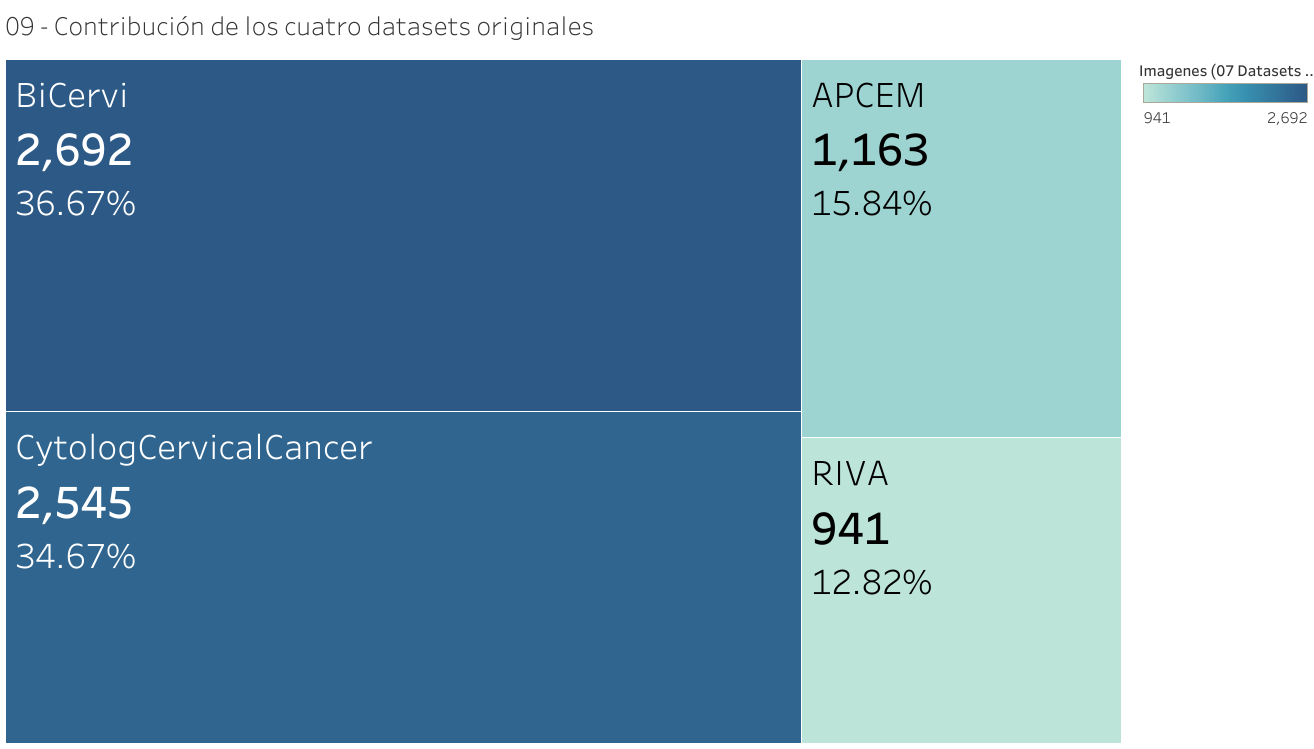

## 2. Configuración de Apache Spark

Instalé PySpark 4.0.1 y las bibliotecas necesarias. Creé la sesión de Spark en **modo local**, de modo qu utilicé dos núcleos para realizar operaciones sobre DataFrames. Dicha configuración permite aplicar la API de Spark en Colab.

Sobre la consulta de prueba `spark.range(5).show()`, esta fue para verificar el funcionamiento del entorno.

In [ ]:
%pip -q install "pyspark==4.0.1" "kagglehub>=1.0.2" pillow pandas

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os, sys, shutil, subprocess
from pathlib import Path
import pyspark

print("Python:", sys.version.split()[0])
print("PySpark:", pyspark.__version__)
print("Java:")
subprocess.run(["java", "-version"], check=True)
print("Espacio libre en /content (GB):", round(shutil.disk_usage("/content").free / 1e9, 2))

Python: 3.13.18
PySpark: 4.0.1
Java:
Espacio libre en /content (GB): 114.19


In [ ]:
from pyspark.sql import SparkSession
spark = (SparkSession.builder
         .appName("BigData_Citologia_Cervical")
         .master("local[2]")
         .config("spark.sql.shuffle.partitions", "4")
         .config("spark.driver.memory", "2g")
         .getOrCreate())
spark.sparkContext.setLogLevel("WARN")
print("Spark:", spark.version)
spark.range(5).show()

Spark: 4.0.1
+---+
| id|
+---+
|  0|
|  1|
|  2|
|  3|
|  4|
+---+



La ejecución registró Python 3.13.18, PySpark/Spark 4.0.1 y una sesión funcional capaz de crear y consultar DataFrames. Con eso ya quedó establecido mi entorno de procesamiento el cual estaré utilizando para mis futuras operaciones.

## 3. Organización y persistencia de resultados

Utilicé Google Drive como ubicación de almacenamiento de inventarios, resultados intermedios, vectores de características, modelo entrenado y tablas de análisis; esto para que pudiera conservar los resultados de las distitnas etapas sin tener que depender exclusivamente de la sesión temporal de Colab.

In [ ]:
from google.colab import drive
from pathlib import Path
drive.mount('/content/drive')
PROJECT_DIR = Path('/content/drive/MyDrive/BigData_Cervical_MLlib')
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
print('Resultados persistentes:', PROJECT_DIR)

Mounted at /content/drive
Resultados persistentes: /content/drive/MyDrive/BigData_Cervical_MLlib


## 4. Descarga de datos desde Kaggle

Usé `kagglehub.dataset_download` para descargar el dataset. Luego de eso medí el volumen de los archivos descargados y también verifiqué cuál era su estructura en carpetas.

In [ ]:
import shutil, kagglehub
from pathlib import Path

free_gb = shutil.disk_usage('/content').free / 1e9
print(f'Espacio libre antes de descargar: {free_gb:.2f} GB')
if free_gb < 10:
    raise RuntimeError('Menos de 10 GB libres. Revisa el almacenamiento disponible antes de descargar un dataset de ~7 GB.')
DATASET_ID = 'robiulhasan21/cervical-cancer-image-largest-dataset'
DATA_DIR = Path(kagglehub.dataset_download(DATASET_ID))
print('Ruta del dataset:', DATA_DIR)
print(f'Espacio libre posterior: {shutil.disk_usage("/content").free/1e9:.2f} GB')

Espacio libre antes de descargar: 114.18 GB


100%|██████████| 6.25G/6.25G [01:11<00:00, 93.6MB/s]

Extracting files...


Ruta del dataset: /root/.cache/kagglehub/datasets/robiulhasan21/cervical-cancer-image-largest-dataset/versions/2
Espacio libre posterior: 107.36 GB


Tengo que la transferencia mostrada por KaggleHub fue de aproximadamente **6.25 GB**; y que el tamaño medido de los archivos disponibles después de la extracción fue de **6.812 GB** (cuyo resultado lo obtuve más adelante).

## 5. Identificación de estructura y volumen

Revisé los archivos que me entregó KaggleHub para así confirmar la cantidad de observaciones, ver si habían archivos comprimidos adicionales y la estructura de los directorios.

In [ ]:
from pathlib import Path
import zipfile
all_files = [p for p in DATA_DIR.rglob('*') if p.is_file()]
total_bytes = sum(p.stat().st_size for p in all_files)
print(f'Archivos encontrados (de cualquier tipo): {len(all_files):,}')
print(f'Tamaño total descargado: {total_bytes/1e9:.3f} GB')
print('Primeros archivos:')
for p in all_files[:20]: print(p.relative_to(DATA_DIR))
zip_files = [p for p in all_files if p.suffix.lower() == '.zip']
print('ZIP internos encontrados:', len(zip_files))

Archivos encontrados (de cualquier tipo): 7,341
Tamaño total descargado: 6.812 GB
Primeros archivos:
Image/HSIL/HSIL_174.jpg
Image/HSIL/HSIL_253.jpg
Image/HSIL/HSIL_17_3.png
Image/HSIL/HSIL_14_6.png
Image/HSIL/HSIL_27_10.png
Image/HSIL/HSIL_255.jpg
Image/HSIL/HSIL_32_11.png
Image/HSIL/HSIL_15_21.png
Image/HSIL/H007C9x4004.jpg
Image/HSIL/HSIL_9_12.png
Image/HSIL/HSIL_303.jpg
Image/HSIL/HSIL_8_1.png
Image/HSIL/H007C6x2056.jpg
Image/HSIL/HSIL_108.jpg
Image/HSIL/HSIL_7 (9).jpg
Image/HSIL/HSIL_30_5.png
Image/HSIL/HSIL_309.jpg
Image/HSIL/HSIL_20_16.png
Image/HSIL/HSIL_73.jpg
Image/HSIL/HSIL_22_2.png
ZIP internos encontrados: 0


Al final tuve que no se identificaron ZIP internos y que las imágenes quedaron accesibles directamente.

In [ ]:
# Preparar una ruta que sirva tanto para datasets extraídos como comprimidos.
EXTRACT_DIR = DATA_DIR
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}
existing_images = [p for p in DATA_DIR.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS]
if existing_images:
    print(f'Hay {len(existing_images):,} imágenes accesibles. No hace falta descomprimir.')
elif zip_files:
    import shutil
    expected_bytes = 0
    for archive in zip_files:
        with zipfile.ZipFile(archive) as z:
            expected_bytes += sum(item.file_size for item in z.infolist())
    if shutil.disk_usage('/content').free < expected_bytes + 2_000_000_000:
        raise RuntimeError('Falta espacio para descomprimir los ZIP internos con margen de 2 GB.')
    EXTRACT_DIR = Path('/content/cervical_unpacked')
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    for archive in zip_files:
        dest = EXTRACT_DIR / archive.stem
        dest.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(archive) as z:
            base = dest.resolve()
            for item in z.infolist():
                if not (base / item.filename).resolve().is_relative_to(base):
                    raise ValueError(f'Ruta insegura dentro de {archive.name}')
            z.extractall(dest)
    print('ZIP internos descomprimidos en:', EXTRACT_DIR)
else:
    raise RuntimeError('No se detectaron imágenes ni ZIP. Comparte la lista de archivos anterior para revisar la estructura.')

Hay 7,341 imágenes accesibles. No hace falta descomprimir.


## 6. Inventario de imágenes

Generé un inventario de rutas, nombres, clase declarada, extensión y tamaño en bytes, de modo que no tuviera que cargar los píxeles de todas las imágenes en la memoria del proceso. Dicho inventario fue convertido en un **DataFrame de PySpark**, en el que se aplicaron agrupaciones y agregaciones por formato. (De modo que usé Spark SQL/DataFrames para organizar y resumir metadatos del conjunto).

In [ ]:
from pathlib import Path
import pandas as pd
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}
rows = []
for path in EXTRACT_DIR.rglob('*'):
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
        rows.append({'ruta': str(path), 'archivo': path.name,
                     'carpeta_padre': path.parent.name, 'extension': path.suffix.lower(),
                     'bytes': path.stat().st_size})
if not rows:
    raise RuntimeError('No se detectaron imágenes en las extensiones previstas. Revisar carpetas.')
inventory_pd = pd.DataFrame(rows)
print('Imágenes encontradas:', len(inventory_pd))
print('Tamaño total de imágenes (GB):', round(inventory_pd['bytes'].sum()/1e9, 3))
print('Extensiones:')
display(inventory_pd['extension'].value_counts().rename_axis('extension').reset_index(name='cantidad'))
print('Carpetas padre (primeras 30):')
display(inventory_pd['carpeta_padre'].value_counts().head(30).rename_axis('carpeta').reset_index(name='cantidad'))
display(inventory_pd.head(5))

Imágenes encontradas: 7341
Tamaño total de imágenes (GB): 6.812
Extensiones:


,extension,cantidad
0,.jpg,6016
1,.png,941
2,.jpeg,384


Carpetas padre (primeras 30):


,carpeta,cantidad
0,NILM,2101
1,HSIL,1550
2,LSIL,1454
3,SCC,1136
4,ASCUS,1100


,ruta,archivo,carpeta_padre,extension,bytes
0,/root/.cache/kagglehub/datasets/robiulhasan21/...,HSIL_174.jpg,HSIL,.jpg,1322452
1,/root/.cache/kagglehub/datasets/robiulhasan21/...,HSIL_253.jpg,HSIL,.jpg,1566755
2,/root/.cache/kagglehub/datasets/robiulhasan21/...,HSIL_17_3.png,HSIL,.png,1669601
3,/root/.cache/kagglehub/datasets/robiulhasan21/...,HSIL_14_6.png,HSIL,.png,1410465
4,/root/.cache/kagglehub/datasets/robiulhasan21/...,HSIL_27_10.png,HSIL,.png,1656438


In [ ]:
from pyspark.sql import functions as F
inventory_spark = spark.createDataFrame(inventory_pd)
print('Esquema del DataFrame PySpark:')
inventory_spark.printSchema()
print('Total en Spark:', inventory_spark.count())
inventory_spark.groupBy('extension').agg(F.count('*').alias('imagenes'),
                                            F.round(F.sum('bytes')/1e6, 2).alias('MB')).orderBy(F.desc('imagenes')).show(truncate=False)
inventory_pd.to_csv(PROJECT_DIR / 'inventario_imagenes.csv', index=False)
print('Inventario respaldado en Drive.')

Esquema del DataFrame PySpark:
root
 |-- ruta: string (nullable = true)
 |-- archivo: string (nullable = true)
 |-- carpeta_padre: string (nullable = true)
 |-- extension: string (nullable = true)
 |-- bytes: long (nullable = true)

Total en Spark: 7341
+---------+--------+-------+
|extension|imagenes|MB     |
+---------+--------+-------+
|.jpg     |6016    |5414.69|
|.png     |941     |1390.32|
|.jpeg    |384     |7.33   |
+---------+--------+-------+

Inventario respaldado en Drive.


Según mis resultados, se identificaron **7,341 imágenes** y un tamaño total de **6.812 GB**. Las clases coincidieron exactamente con las cantidades que fueron descritas por el repositorio. En términos extensión, hubo **6,016 .jpg (81.95%)**, **941 .png (12.82%)** y **384 .jpeg (5.23%)**.

Debido a la diversidad de formatos y tamaños que había, me decidí por realizar una revisión de dimensiones, modos de color y consistencia. Las agregaciones por extensión las hice con funciones de PySpark (`groupBy`, `count`, `sum`), mientras que el recorrido inicial del sistema de archivos lo implementé en Python.

A continuación presento de una forma más gráfica como fue la distribución de las imágenes.

Link: https://public.tableau.com/app/profile/jorge.manuel.oyoqui.aguilera/viz/ProyectoBigData_17939473138950/10-Volumendealmacenamientoporextensin?publish=yes

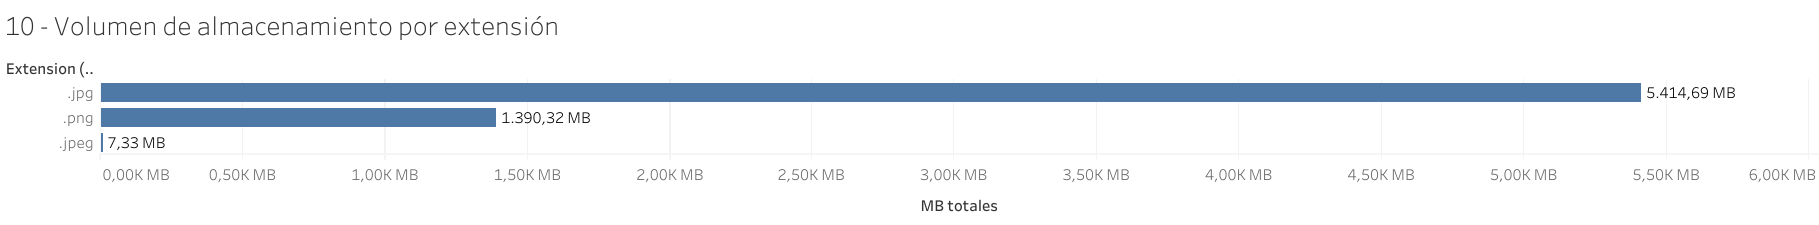

Los archivos JPG concentraron aproximadamente 5,414.69 MB del almacenamiento, seguidos por los PNG con 1,390.32 MB, mienteas que los 384 archivo JPEG ocuparon nada más 7.33 MB. Esta diferencia implica que la cantidad de imágenes no determina en sí cuál es el volumen de almacenamiento, de modo que también es importante considerar aspectos como la resolución y la compresión para de esa forma generar un plan para el procesamiento de grandes volúmenes de información.

## 7. Evaluación de calidad y depuración

Antes de realizar las particiones par los conjuntos Train, Validation y Test, analicé la integridad, formatos de color, resolución, duplicación exacta y posibles relaciones entre archivos. Esta etapa fue esencial para así evitar que hubieran errores de etiquetado o que copias idénticas generaran estimaciones demasiado optimistas del desempeño.

### 7.1. Integridad, color y dimensiones

Utilicé Pillow para revisar los metadatos de cada imagen y y también para ejecutar `Image.verify()`. Registré las dimensiones, modo de color y tipo de archivo. Con esta verificación revisé si es que habían problemas de lectura a nivel de archivo, pero me gustaría aclarar que no garantiza como tal la validez clínica de su contenido ni una decodificación perfecta en todos los contextos.

In [ ]:
import pandas as pd
from PIL import Image, UnidentifiedImageError
from pathlib import Path

QUALITY_FILE = PROJECT_DIR / 'calidad_imagenes.csv'
if QUALITY_FILE.exists():
    quality_previous = pd.read_csv(QUALITY_FILE)
    quality_records = quality_previous.to_dict('records')
    done = set(quality_previous['ruta'].astype(str))
    print(f'Reanudando: {len(done):,} imágenes ya inspeccionadas')
else:
    quality_records, done = [], set()

def inspect_image(ruta):
    try:
        with Image.open(ruta) as im:
            fmt, mode, width, height = im.format, im.mode, *im.size
            im.verify()
        return {'ruta': ruta, 'ancho': width, 'alto': height,
                'modo': mode, 'formato_detectado': fmt, 'valida': True, 'error': ''}
    except Exception as exc:
        return {'ruta': ruta, 'ancho': None, 'alto': None,
                'modo': None, 'formato_detectado': None,
                'valida': False, 'error': f'{type(exc).__name__}: {str(exc)[:180]}'}

pending = [str(p) for p in inventory_pd['ruta'] if str(p) not in done]
for i, ruta in enumerate(pending, 1):
    quality_records.append(inspect_image(ruta))
    if i % 500 == 0:
        pd.DataFrame(quality_records).to_csv(QUALITY_FILE, index=False)
        print(f'Procesadas en esta ejecución: {i:,}/{len(pending):,}')
quality_pd = pd.DataFrame(quality_records)
quality_pd.to_csv(QUALITY_FILE, index=False)
print('Inspeccionadas:', len(quality_pd), 'Válidas:', int(quality_pd['valida'].sum()),
      'Inválidas:', int((~quality_pd['valida']).sum()))
display(quality_pd.loc[~quality_pd['valida'], ['ruta','error']].head(20))

Reanudando: 14,682 imágenes ya inspeccionadas
Inspeccionadas: 14682 Válidas: 14682 Inválidas: 0


,ruta,error


In [ ]:
valid_pd = quality_pd.loc[quality_pd['valida']].copy()
print('Modos de color:')
display(valid_pd['modo'].value_counts(dropna=False).rename_axis('modo').reset_index(name='imagenes'))
print('Formatos detectados por Pillow:')
display(valid_pd['formato_detectado'].value_counts(dropna=False).rename_axis('formato').reset_index(name='imagenes'))
print('Estadísticas de resolución (píxeles):')
display(valid_pd[['ancho','alto']].describe().round(1))
print('Combinaciones ancho × alto más frecuentes:')
display(valid_pd.groupby(['ancho','alto']).size().sort_values(ascending=False).head(15).rename('imagenes').reset_index())
valid_pd['megapixeles'] = (valid_pd['ancho'] * valid_pd['alto']) / 1e6
print('Distribución de megapíxeles:')
display(valid_pd['megapixeles'].describe(percentiles=[.05,.25,.5,.75,.95]).round(3))

Modos de color:


,modo,imagenes
0,RGB,14682


Formatos detectados por Pillow:


,formato,imagenes
0,JPEG,12800
1,PNG,1882


Estadísticas de resolución (píxeles):


,ancho,alto
count,14682.0,14682.0
mean,1946.0,1503.3
std,887.1,614.4
min,224.0,224.0
25%,1024.0,1024.0
50%,2560.0,1920.0
75%,2592.0,1944.0
max,2592.0,1944.0


Combinaciones ancho × alto más frecuentes:


,ancho,alto,imagenes
0,2592,1944,5384
1,2560,1920,3166
2,2048,1536,1924
3,1024,1024,1882
4,224,224,1558
5,384,384,768


Distribución de megapíxeles:


,megapixeles
count,14682.000
mean,3.467
std,1.984
min,0.050
5%,0.050
25%,1.049
50%,4.915
75%,5.039
95%,5.039
max,5.039


El análisis verificó correctamente **7,341 de 7,341 archivos**. Tampoco encontró que hubieran imágenes ilegibles en las comprobaciones realizadas. Todas las imágenes estaban en modo **RGB**. Igualmente, se identificó que la imágenes tenían **seis resoluciones**: 224×224, 384×384, 1024×1024, 2048×1536, 2560×1920 y 2592×1944 píxeles. La resolución mediana fue de **2560×1920**, mientras que la resolución máxima fue de **2592×1944**. El promedio de megapíxeles fue **3.467**.

Debido a la heterogeneidad de los tamaños, decidí aplicar un preprocesamiento uniforme para conservar la proporción visual pero que a su vez permitiera ajustar las entradas del extractor a 224×224 píxeles.

A continuación presento quedó la distribución de resoluciones antes del redimensionamiento.

Link: https://public.tableau.com/app/profile/jorge.manuel.oyoqui.aguilera/viz/ProyectoBigData_17939473138950/11_Histogramademegapxeles?publish=yes

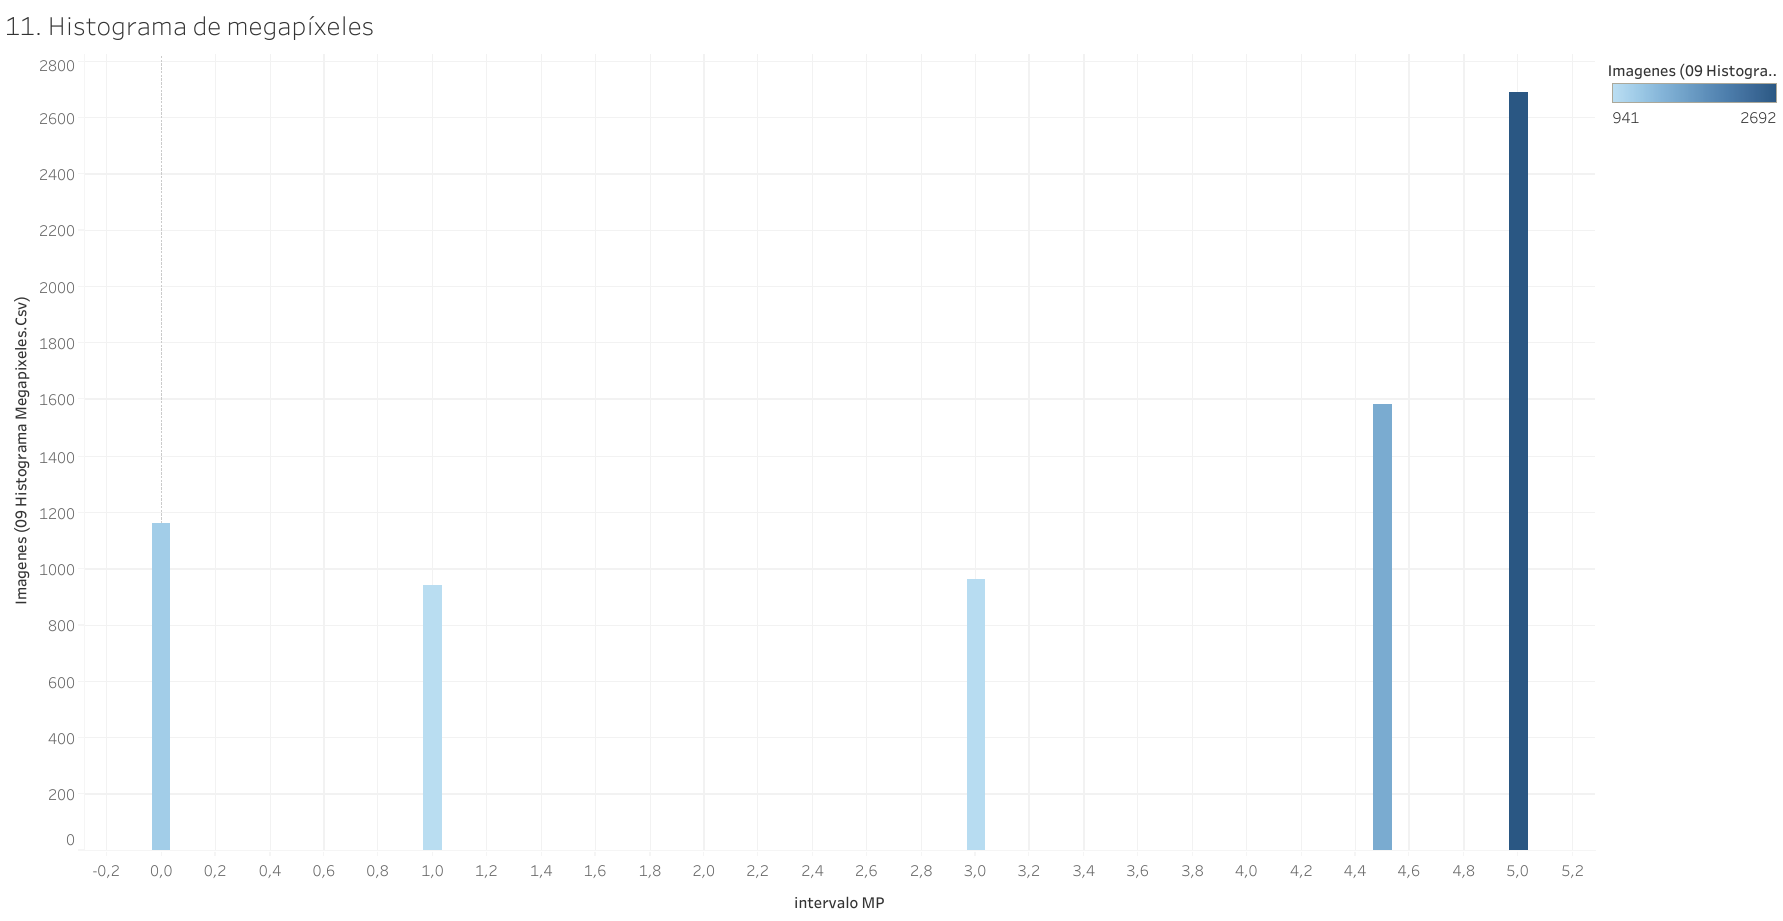

La distribución de megapíxeles tuvo concentraciones en varias resoluciones específicas, en vez de tener una distribución uniforme. Identifiqué  que hubieron imágenes desde aproximadamente 0.05 hasta 5.04 megapíxeles, de modo que hubo una gran concentración cerca de los cinco megapíxeles. COn dicho  resultado puedo justificar más mis decisión de hacer el redimensionamiento a 224 x 224 píxeles, lo cual fue necesario para tener una entrada de tamaño unifrome antes de que empezara a utilizar MobileNetV2.

### 7.2. Detección de duplicados exactos

A continuación, calculé el hash **SHA-256** de cada archivo a través de ima lectura por bloques, de modo que aquellos archivos que tuviera el mismo hash tendrían exactamente los mismos bytes, independientemente de su nombre. Es decir, serían duplicados exactos.

**Aclaración:** Esta prueba sólo me ayudó para los duplciados exactos, pero no para que fueran imágenes **visualmente similares, recortes o distintas capturas de la misma muestra**.

In [ ]:
import hashlib
HASH_FILE = PROJECT_DIR / 'hashes_imagenes.csv'
if HASH_FILE.exists():
    hash_old = pd.read_csv(HASH_FILE, dtype=str)
    hash_records = hash_old.to_dict('records')
    hashed = set(hash_old['ruta'].astype(str))
    print('Hashes recuperados:', len(hashed))
else:
    hash_records, hashed = [], set()

def sha256_file(filepath):
    digest = hashlib.sha256()
    with open(filepath, 'rb') as file:
        while True:
            chunk = file.read(1024 * 1024)
            if not chunk: break
            digest.update(chunk)
    return digest.hexdigest()

remaining = [str(p) for p in inventory_pd['ruta'] if str(p) not in hashed]
for i, ruta in enumerate(remaining, 1):
    try:
        hash_records.append({'ruta': ruta, 'sha256': sha256_file(ruta), 'error_hash': ''})
    except Exception as exc:
        hash_records.append({'ruta': ruta, 'sha256': '', 'error_hash': str(exc)[:180]})
    if i % 250 == 0:
        pd.DataFrame(hash_records).to_csv(HASH_FILE, index=False)
        print(f'Hashes de esta ejecución: {i:,}/{len(remaining):,}')
hash_pd = pd.DataFrame(hash_records)
hash_pd.to_csv(HASH_FILE, index=False)
print('Registros con hash:', hash_pd['sha256'].fillna('').ne('').sum())
print('Errores de lectura:', hash_pd['error_hash'].fillna('').ne('').sum())

Hashes recuperados: 14682
Registros con hash: 14682
Errores de lectura: 0


In [ ]:
hash_labeled = inventory_pd[['ruta','carpeta_padre','archivo']].merge(
    hash_pd[['ruta','sha256']], on='ruta', how='left')
nonempty_hashes = hash_labeled.loc[hash_labeled['sha256'].fillna('').ne('')].copy()
counts = nonempty_hashes.groupby('sha256').size()
duplicate_hashes = counts[counts > 1].index
duplicate_rows = nonempty_hashes.loc[nonempty_hashes['sha256'].isin(duplicate_hashes)].sort_values('sha256')
print('Grupos de duplicados exactos:', len(duplicate_hashes))
print('Archivos en grupos duplicados:', len(duplicate_rows))
print('Copias redundantes:', int((counts - 1).clip(lower=0).sum()))
print('Grupos con etiquetas de clases distintas:')
if not duplicate_rows.empty:
    conflicts = duplicate_rows.groupby('sha256')['carpeta_padre'].nunique()
    print(int((conflicts > 1).sum()))
    display(duplicate_rows[['sha256','carpeta_padre','archivo']].head(35))
else:
    print(0)
duplicate_rows.to_csv(PROJECT_DIR / 'duplicados_exactos.csv', index=False)

Grupos de duplicados exactos: 324
Archivos en grupos duplicados: 933
Copias redundantes: 609
Grupos con etiquetas de clases distintas:
112


,sha256,carpeta_padre,archivo
1588,017d06dfe985fc2284d3bf929e345654c2c56376a9ca9d...,ASCUS,ASC-US_252.jpg
4250,017d06dfe985fc2284d3bf929e345654c2c56376a9ca9d...,NILM,NILM_372.jpg
5906,017d06dfe985fc2284d3bf929e345654c2c56376a9ca9d...,NILM,NILM_910.jpg
4541,017d06dfe985fc2284d3bf929e345654c2c56376a9ca9d...,NILM,NILM_575.jpg
5714,02873c6c23926c149f9e52b47c7dbdde1105b0216b0648...,NILM,NILM_1049.jpg
4653,02873c6c23926c149f9e52b47c7dbdde1105b0216b0648...,NILM,NILM_1024.jpg
4311,029924fe2531a31b08ab265e00859251c2d99ae9577390...,NILM,NILM_750.jpg
2531,029924fe2531a31b08ab265e00859251c2d99ae9577390...,ASCUS,ASC-US_195.jpg
1425,0365726b6248f621e6b790f3584f2e2972b621c9411e13...,HSIL,HSIL_315.jpg
181,0365726b6248f621e6b790f3584f2e2972b621c9411e13...,HSIL,HSIL_349.jpg


Tuve que se detectaron **324 grupos de duplicados exactos**, los cuales reunieron **933 archivos**, con **609 copias redundantes**. De estos grupos, **112 presentaron etiquetas citológicas distintas para archivos idénticos**, de modo que esto se trató de una inconsistencia por parte del material original. Esto fue un problema debido a que la presencia de etiquetas contradictorias me impediría asignar una clase confiable usando únicamente los nombres o la frecuencia de etiquetas.

Por ello decidí excluir los grupos conflictivos y conservar solamente una copia en los grupos de duplicados con etiquetas que furon consistentes. De esta forma pude reducir el riesgo de introducir observaciones idénticas en diferentes particiones, aunque no puedo afirmar con total certeza que eliminé todas las fuentes posibles de fuga de información.

Ahora, voy a mostrar visualmente como fue el estados de los duplicados por categoría.

Link: https://public.tableau.com/app/profile/jorge.manuel.oyoqui.aguilera/viz/ProyectoBigData_17939473138950/12_Estadodelosduplicadosporcategora?publish=yes

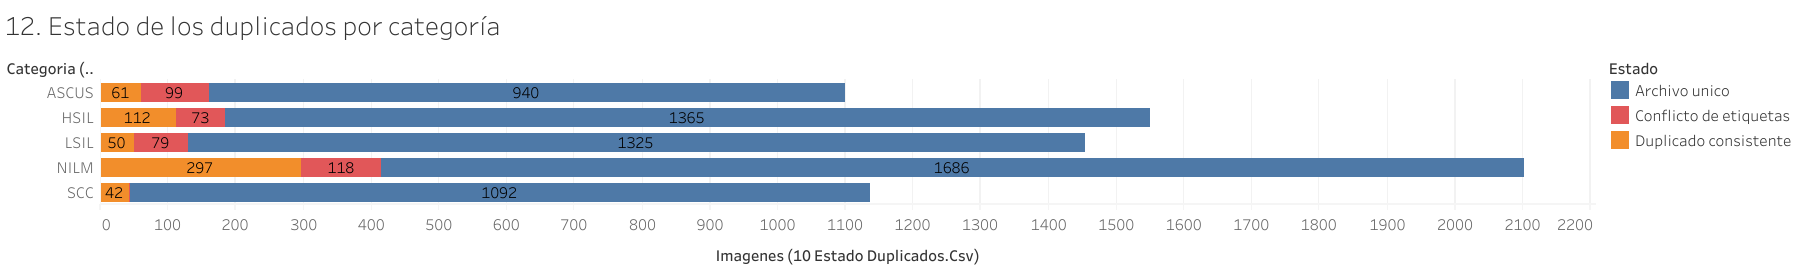

Este gráfico me permite diferencias a aquellos archivos que son únicos de aquellas que pertenecen a grupos de duplicados consistenetes y aquellas con conflictos de etiquetas. En total, identifiqué 324 gruposde duplicados exactos,de los cuales 112 tuvieron categorías contradictorias. Esta visualización me facilita identificar qué clases estaban afectadas y le dio más solidez a mi decisión de excluir las 371 imágenes conflictivas antes de que pasara a la fase de entrenamiento.

### 7.3. Patrones de nombres y posibles muestras relacionadas

Examiné los prefijos y la estructuras de los nombres para revisar si es que habían secuencias, aumentos o imágenes de una misma muestra. Los patrones que detecté los traté como **evidencia heurística**, no como identificadores clínicos.

In [ ]:
import re
file_review = inventory_pd[['carpeta_padre','archivo','ruta']].copy()
file_review['prefijo_inicial'] = file_review['archivo'].str.extract(r'^([A-Za-z]+)', expand=False).fillna('(sin letras iniciales)')
print('Prefijos por clase (20 más frecuentes):')
display(file_review.groupby(['carpeta_padre','prefijo_inicial']).size().sort_values(ascending=False).head(20).rename('imagenes').reset_index())
print('Ejemplos por clase y prefijo:')
display(file_review.sort_values('archivo').groupby(['carpeta_padre','prefijo_inicial']).head(3)[['carpeta_padre','prefijo_inicial','archivo']].head(60))
file_review[['carpeta_padre','archivo','prefijo_inicial']].to_csv(PROJECT_DIR / 'patrones_nombres.csv', index=False)

Prefijos por clase (20 más frecuentes):


,carpeta_padre,prefijo_inicial,imagenes
0,NILM,NILM,1489
1,HSIL,HSIL,901
2,ASCUS,ASC,844
3,LSIL,LSIL,839
4,HSIL,H,649
5,NILM,NL,612
6,LSIL,L,465
7,SCC,SSC,453
8,SCC,C,279
9,SCC,(sin letras iniciales),234


Ejemplos por clase y prefijo:


,carpeta_padre,prefijo_inicial,archivo
3965,LSIL,(sin letras iniciales),"001_(10367,9080,5).jpeg"
3219,LSIL,(sin letras iniciales),"001_(11165,4705,6).jpeg"
3157,LSIL,(sin letras iniciales),"001_(12513,7297,4).jpeg"
6285,SCC,(sin letras iniciales),"001_(13769,5590,8).jpeg"
6882,SCC,(sin letras iniciales),"001_(5259,12811,7).jpeg"
7165,SCC,(sin letras iniciales),"001_(5946,8274,5).jpeg"
1586,ASCUS,A,A001x10C1.jpg
1831,ASCUS,A,A001x10C2.jpg
2075,ASCUS,A,A001x10D1.jpg
2219,ASCUS,ASC,ASC-US_1.jpg


A continuación, presento gráficamente cuantos prefijos de nombres por categoría hubieron.

Link: https://public.tableau.com/app/profile/jorge.manuel.oyoqui.aguilera/viz/ProyectoBigData_17939473138950/13_Prefijosdenombreporcategora?publish=yes

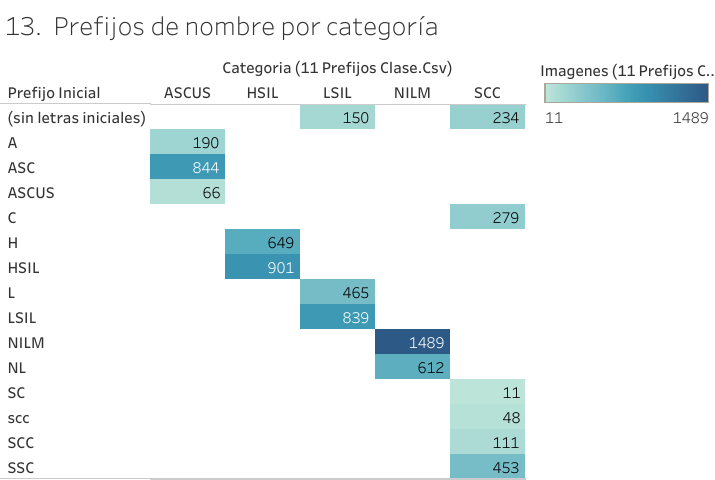

Con este análisis pude revelar que habían varias convenciones para nombrar los archivos, como H, HSIL, NL, NILM, SSC y SCC. Que existieran varios patrones sugiere que hubo diferencias en las organizaciones de las colecciones originales y la posibildiad de que algunas imágenes sean parte de secuencias relacionadas. Dicho hallazgo fue lo que me motivó a hacer un análisis posterior a través de expresioens regulares para así reducir el riesgo de separar observaciones potencialmente relacionadas entre las particiones.

### 7.4. Resumen agregado por categoría

Ahora, integré los metadatos de tamaño, dimensiones y validez en un DataFrame de Spark, de modo que a través de `groupBy` y funciones agregadas (como `count`, `sum` o `avg`) calculé las cantidades, tamaños y dimensiones promedio por categoría. Dichos resultados los explorté a un CSV para usarlos posteriormente en Tableau.

In [ ]:
from pyspark.sql import functions as F
analysis_pd = (inventory_pd.merge(quality_pd, on='ruta', how='left')
               .merge(hash_pd[['ruta','sha256']], on='ruta', how='left'))
analysis_spark = spark.createDataFrame(analysis_pd.fillna({'modo':'DESCONOCIDO','formato_detectado':'DESCONOCIDO','sha256':''}))
tableau_classes = (analysis_spark.groupBy('carpeta_padre')
    .agg(F.count('*').alias('n_imagenes'),
         F.round(F.sum('bytes')/1e9,3).alias('tamano_GB'),
         F.round(F.avg('ancho'),1).alias('ancho_promedio'),
         F.round(F.avg('alto'),1).alias('alto_promedio'),
         F.sum(F.when(F.col('valida') == False, 1).otherwise(0)).alias('imagenes_invalidas'))
    .orderBy('carpeta_padre'))
tableau_classes.show(truncate=False)
tableau_classes.toPandas().to_csv(PROJECT_DIR / 'tableau_resumen_clases.csv', index=False)
analysis_pd.to_csv(PROJECT_DIR / 'metadatos_calidad_completos.csv', index=False)
print('Exportaciones guardadas en Drive.')

+-------------+----------+---------+--------------+-------------+------------------+
|carpeta_padre|n_imagenes|tamano_GB|ancho_promedio|alto_promedio|imagenes_invalidas|
+-------------+----------+---------+--------------+-------------+------------------+
|ASCUS        |1100      |0.652    |1790.6        |1374.9       |0                 |
|HSIL         |1550      |1.452    |2176.4        |1688.6       |0                 |
|LSIL         |1454      |1.236    |1872.8        |1486.2       |0                 |
|NILM         |2101      |3.096    |2402.2        |1806.8       |0                 |
|SCC          |1136      |0.376    |1032.3        |835.5        |0                 |
+-------------+----------+---------+--------------+-------------+------------------+

Exportaciones guardadas en Drive.


In [ ]:
# Número de etiquetas diferentes por hash
etiquetas_por_hash = (
    hash_labeled
    .groupby("sha256")["carpeta_padre"]
    .nunique()
)

# Hashes con etiquetas contradictorias
hashes_conflictivos = etiquetas_por_hash[
    etiquetas_por_hash > 1
].index

# Imágenes pertenecientes a grupos conflictivos
imagenes_conflictivas = hash_labeled[
    hash_labeled["sha256"].isin(hashes_conflictivos)
]

print("Grupos conflictivos:", len(hashes_conflictivos))
print("Imágenes en grupos conflictivos:", len(imagenes_conflictivas))

Grupos conflictivos: 112
Imágenes en grupos conflictivos: 371


In [ ]:
# Excluir todas las imágenes de grupos conflictivos
df_sin_conflictos = hash_labeled[
    ~hash_labeled["sha256"].isin(hashes_conflictivos)
].copy()

# Conservar una imagen por hash
df_limpio = df_sin_conflictos.drop_duplicates(
    subset="sha256",
    keep="first"
).copy()

print("Imágenes originales:", len(hash_labeled))
print("Imágenes excluidas por conflictos:", len(imagenes_conflictivas))
print("Imágenes finales:", len(df_limpio))

print("\nDistribución final por clase:")
print(df_limpio["carpeta_padre"].value_counts())

# Guardar sin modificar los archivos originales
df_limpio.to_csv(
    PROJECT_DIR / "inventario_limpio_preliminar.csv",
    index=False
)

Imágenes originales: 7341
Imágenes excluidas por conflictos: 371
Imágenes finales: 6620

Distribución final por clase:
carpeta_padre
NILM     1790
HSIL     1409
LSIL     1345
SCC      1113
ASCUS     963
Name: count, dtype: int64


Tras haber exluído 371 archivos de grupos conflictivos y 350 copias adicionales de grupos consistentes, quedaron 6,620 imágenes únicas según SHA-256.

**Aclaración:** La cifra de 609 copias redundantes identificada inicialmente incluyó copias situadas en los grupos contradictorios. Justo por eso fue que no lo sumé directamente a las 371 exclusiones.

Ahora presento de forma gráfica cuál fue la cantidad de imágenes frente al volumne por categoría.

Link: https://public.tableau.com/app/profile/jorge.manuel.oyoqui.aguilera/viz/ProyectoBigData_17939473138950/14_Cantidaddeimgenesfrentealvolumenporcategora?publish=yes

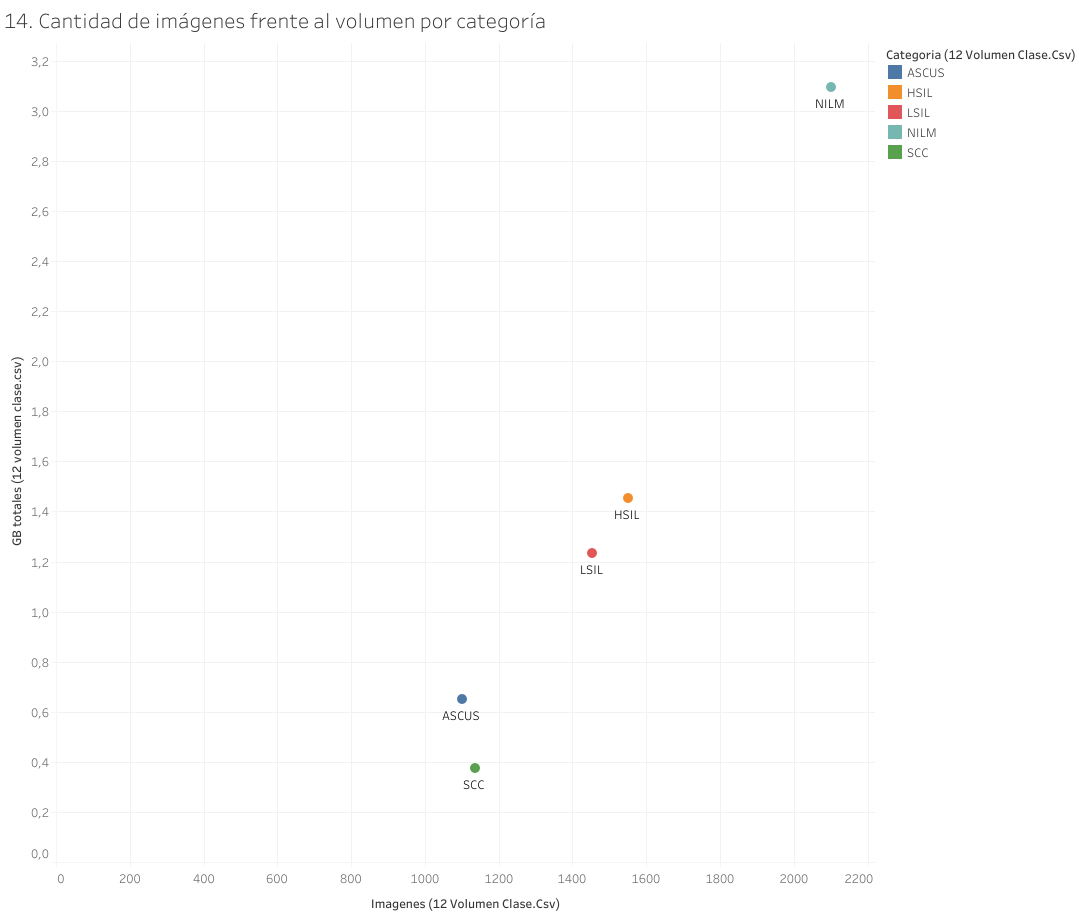

La gráfica muesta que aquellas categorías que tuvieron una mayor cantidad de imágenes también presentaron un mayor volumen de almacenamiento. Pero la relación no fue directamente proporcional, ya que NILM contuvo 2,101 imágenes y ocupó aproximadamente 3.096 GB, mientras que SCC contuvo 1,136 imágenes yy ocupó solamente 0.376 GB. Esto implica quie hay diferencias en las carcaterísticas de los archivos, lo cual considero que justifica mi decisión de considerar tanto el número de observaciones como su tamañoi al evaluar el volumen del dataset.

## 8. Caracterización del conjunto limpio

En la limpieza terminé excluyendo **371 archivos** pertenecientes a los 112 grupos con etiquetas contradictorias y **350 copias redundantes adicionales**. Así que el conjunto pasó de tener 7,341 imágenes a tener 6,620 (lo cual es aproximadamente el 90.18% del conjunto original).

**Aclaración:** No eliminé los archivos originales del almacenamiento, solamente generé un inventario de selección.

| Categoría | Original | Después de la limpieza |
|---|---:|---:|
| NILM | 2,101 | 1,790 |
| ASCUS | 1,100 | 963 |
| LSIL | 1,454 | 1,345 |
| HSIL | 1,550 | 1,409 |
| SCC | 1,136 | 1,113 |
| **Total** | **7,341** | **6,620** |

Al final se mantuvieron las cinco categorías.

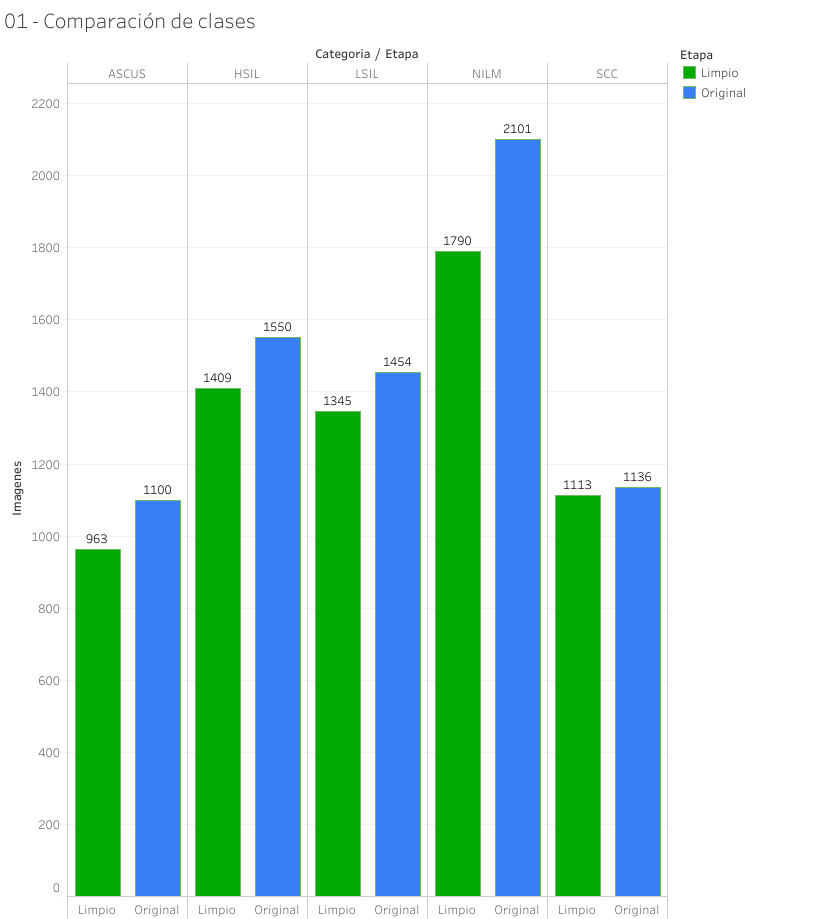

Link https://public.tableau.com/app/profile/jorge.manuel.oyoqui.aguilera/viz/ProyectoBigData_17939473138950/01-Comparacindeclases?publish=yes

In [ ]:
import pandas as pd
from pathlib import Path
df_limpio = pd.read_csv(PROJECT_DIR / 'inventario_limpio_preliminar.csv')
print('Inventario limpio:', len(df_limpio))
assert df_limpio['sha256'].notna().all() and df_limpio['sha256'].is_unique
display(df_limpio['carpeta_padre'].value_counts())

Inventario limpio: 6620


,count
carpeta_padre,
NILM,1790
HSIL,1409
LSIL,1345
SCC,1113
ASCUS,963


### 8.1. Asociación entre resolución y categoría

Crucé la resolución con la clase en el conjunto limpio, de modo que obtuve los siguientes resultados:
- **224×224** apareció solo en ASCUS y SCC
- **384×384** apareció solo en LSIL y SCC
- **2560×1920** no incluyó NILM.

Esto implica que puede que la procedencia esté asociada con las etiquetas. Por ende, el modelo podría llegar a aprender señales de la fuente además de las características celulares, aunque me temo que con este resultado no puedo demostrar cuál es la procedencia exacta de cada imagen.

In [ ]:
quality_small = pd.read_csv(PROJECT_DIR / 'calidad_imagenes.csv', usecols=['ruta','ancho','alto'])
diagnosis = df_limpio[['ruta','archivo','carpeta_padre']].merge(quality_small, on='ruta', how='left', validate='one_to_one')
diagnosis['resolucion'] = diagnosis['ancho'].astype('Int64').astype(str) + 'x' + diagnosis['alto'].astype('Int64').astype(str)
counts = pd.crosstab(diagnosis['resolucion'], diagnosis['carpeta_padre'])
display(counts)
print('Distribución de clases dentro de cada resolución (%)')
display((counts.div(counts.sum(axis=1),axis=0)*100).round(1))
counts.to_csv(PROJECT_DIR / 'tableau_resolucion_clase.csv')

carpeta_padre,ASCUS,HSIL,LSIL,NILM,SCC
resolucion,,,,,
1024x1024,66,341,407,42,85
2048x1536,0,163,113,612,74
224x224,326,0,0,0,433
2560x1920,190,649,465,0,279
2592x1944,381,256,210,1136,8
384x384,0,0,150,0,234


Distribución de clases dentro de cada resolución (%)


carpeta_padre,ASCUS,HSIL,LSIL,NILM,SCC
resolucion,,,,,
1024x1024,7.0,36.2,43.3,4.5,9.0
2048x1536,0.0,16.9,11.7,63.6,7.7
224x224,43.0,0.0,0.0,0.0,57.0
2560x1920,12.0,41.0,29.4,0.0,17.6
2592x1944,19.1,12.9,10.5,57.1,0.4
384x384,0.0,0.0,39.1,0.0,60.9


En el conjunto ya limpio, las imágenes de 224×224 pertenecieron exclusivamente a ASCUS y SCC, mientras que las de 384×384 pertenecieron exclusivamente a LSIL y SCC.

Igualmente, la asociación entre resolución y clase puede llegar a facilitar que un modelo aprenda señales relacionadas con la fuente de los archivos, de modo que esta sería una limitación de mi  evaluación.

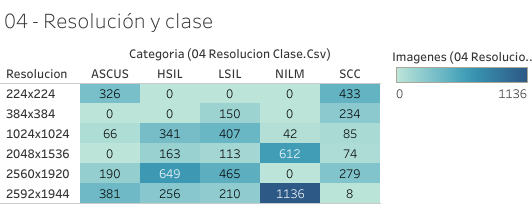

Link: https://public.tableau.com/app/profile/jorge.manuel.oyoqui.aguilera/viz/ProyectoBigData_17939473138950/04-Resolucinyclase?publish=yes

### 8.2. Identificación preliminar de familias de imágenes

A través de expresiones regulares se reconocieron patrones como `H005C3x...`, `ASCUS_1_10.png` y `SSC_02 (343).jpg`. Con el diagnóstico inicial pude identifiar **150 familias candidatas** con **2,732 imágenes** agrupadas. Debido a eso decidí hacer una separación de datos que conservara grupos completos, evitando dividir entre conjuntos los archivos reconocidos como potencialmente relacionados.

**Aclaración:** Como no dispongo de identificadores validados de paciente o muestra, puedo considerar este caso como una limitación de mi metodológia.

In [ ]:
import re
def candidate_family(filename):
    stem = Path(filename).stem
    x = re.match(r'^([AHLC])(\d{3})(?=C\d|x\d)', stem, re.I)
    if x: return ('microscopia',x.group(1).upper()+x.group(2))
    x = re.match(r'^(ASCUS|HSIL|LSIL|NILM|SCC)_(\d+)_(\d+)$', stem, re.I)
    if x: return ('subimagen',x.group(1).upper()+'_'+x.group(2))
    x = re.match(r'^(SSC|NL|HSIL|LSIL|scc)_(\d+)\s*\(\d+\)$', stem, re.I)
    if x: return ('parentesis',x.group(1).upper()+'_'+x.group(2))
    return ('sin_patron',None)
diagnosis[['tipo_patron','familia_candidata']] = diagnosis['archivo'].apply(lambda x: pd.Series(candidate_family(x)))
display(diagnosis['tipo_patron'].value_counts())
display(diagnosis.groupby('tipo_patron').head(8)[['carpeta_padre','archivo','tipo_patron','familia_candidata']])

,count
tipo_patron,
sin_patron,3888
microscopia,1089
subimagen,860
parentesis,783


,carpeta_padre,archivo,tipo_patron,familia_candidata
0,HSIL,HSIL_174.jpg,sin_patron,None
1,HSIL,HSIL_17_3.png,subimagen,HSIL_17
2,HSIL,HSIL_14_6.png,subimagen,HSIL_14
3,HSIL,HSIL_27_10.png,subimagen,HSIL_27
4,HSIL,HSIL_32_11.png,subimagen,HSIL_32
5,HSIL,HSIL_15_21.png,subimagen,HSIL_15
6,HSIL,H007C9x4004.jpg,microscopia,H007
7,HSIL,HSIL_9_12.png,subimagen,HSIL_9
8,HSIL,HSIL_303.jpg,sin_patron,None
9,HSIL,HSIL_8_1.png,subimagen,HSIL_8


In [ ]:
candidates = diagnosis.dropna(subset=['familia_candidata']).copy()
candidates['grupo_candidato'] = candidates['tipo_patron'] + ':' + candidates['carpeta_padre'] + ':' + candidates['familia_candidata']
groups = candidates.groupby('grupo_candidato').agg(n_imagenes=('ruta','size'), ejemplo_1=('archivo','first'), ejemplo_2=('archivo','last')).sort_values('n_imagenes',ascending=False)
print('Familias candidatas:',len(groups))
print('Familias con 2+ imágenes:',int((groups['n_imagenes']>1).sum()))
print('Imágenes dentro de familias de 2+:',int(groups.loc[groups['n_imagenes']>1,'n_imagenes'].sum()))
display(groups.head(30))
groups.to_csv(PROJECT_DIR / 'familias_candidatas.csv')
diagnosis.to_csv(PROJECT_DIR / 'diagnostico_patrones_etapa3.csv',index=False)

Familias candidatas: 150
Familias con 2+ imágenes: 150
Imágenes dentro de familias de 2+: 2732


,n_imagenes,ejemplo_1,ejemplo_2
grupo_candidato,,,
parentesis:SCC:SSC_02,358,SSC_02 (53).jpg,SSC_02 (278).jpg
microscopia:SCC:C002,156,C002x20_09.jpg,C002x20_73.jpg
microscopia:SCC:C003,108,C003x20_49.jpg,C003x20_60.jpg
microscopia:HSIL:H006,107,H006C3x1064.jpg,H006C3x40106.jpg
microscopia:HSIL:H005,105,H005C1x40008.jpg,H005C2x40036.jpg
microscopia:HSIL:H007,92,H007C9x4004.jpg,H007C6x4065.jpg
parentesis:SCC:SSC_01,75,SSC_01 (47).jpg,SSC_01 (72).jpg
microscopia:ASCUS:A005,64,A005x20o101.jpg,A005x40D50201.jpg
microscopia:LSIL:L001,61,L001C1x20006.jpg,L001C2x20038.jpg


A continaución, en el siguiente dashboard presento  cómo quedó la distribución del tamaño de las familias candidatas.

Link: https://public.tableau.com/app/profile/jorge.manuel.oyoqui.aguilera/viz/ProyectoBigData_17939473138950/15_Distribucindelasfamiliascandidatas?publish=yes

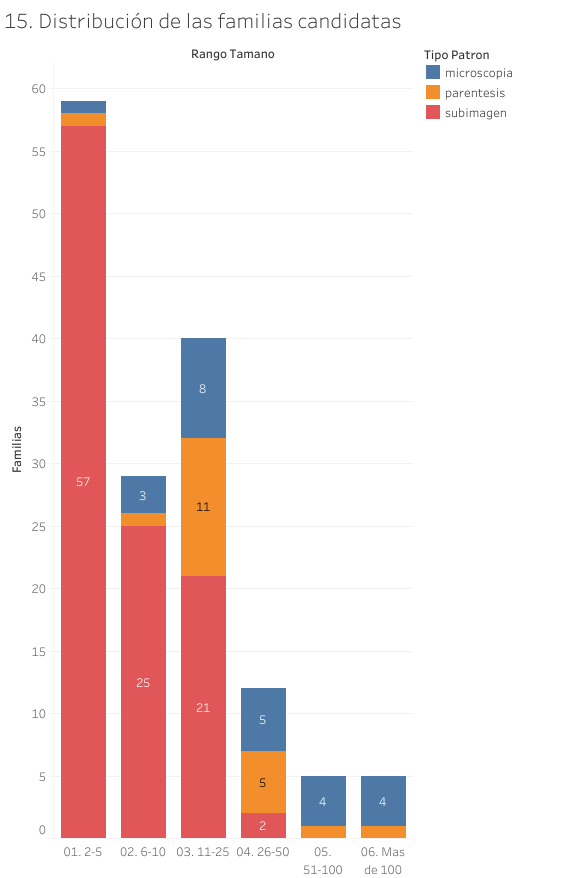

Identifiqué 150 familias candidatas que agruparon 2,732 imágenes. La distribución del tamaño de estas familias me permite poder distinguir grupos pequeños de agrupaciones que contienen varias observaciones, como por ejemplo algunas secuencias de microscopía. Dicho análisis me fue útil para justificar una partición que mantuviera juntas las imágenes portencialmente relacionadas, evitando así que los grupos completos se dividieran entre entrenamiento y prueba.

## 9. Diseño de particiones para entrenamiento y evaluación

Dividó mi cpnjunto limpio aproximadamente en **70% entrenamiento, 15% validación y 15% prueba**. Implementé una asignación por clase y por grupos heurísticos de archivos, de modo que pudiera conservar agrupaciones completas y mantener las cinco categorías representadas. Lo que busqué con esta estrategia fue reducir la fuga de información, aunque esto no garantiza que haya independencia de pacientes ni elimina posibles sesgos de adquisición.

### 9.1. Recuperación y validación del inventario limpio

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
import re

clean_csv = PROJECT_DIR / 'inventario_limpio_preliminar.csv'
if not clean_csv.exists():
    raise FileNotFoundError('Falta inventario_limpio_preliminar.csv en Drive. Primero ejecutar la limpieza de duplicados.')
df_split = pd.read_csv(clean_csv, dtype={'sha256':str})
assert len(df_split) == 6620, f'Se esperaba 6620 registros, recibidos {len(df_split)}.'
assert df_split['sha256'].notna().all() and df_split['sha256'].is_unique
assert df_split['ruta'].is_unique
print('Registros:',len(df_split))
display(df_split['carpeta_padre'].value_counts())

Registros: 6620


,count
carpeta_padre,
NILM,1790
HSIL,1409
LSIL,1345
SCC,1113
ASCUS,963


### 9.2. Definición de grupos para la separación

A conitnuación, utilipce los patrones de nombre para agrupar los archivos que pudieran estar potencialmente relacionados. A los archivos que no tuvieron un patrón reconocido los traté como si fueran unidades individuales. Al final, obtuve **3,550 grupos**, de los cuales **150** contenían más de una imagen.

In [ ]:
def heuristic_group(class_name, filename, sha256):
    stem = Path(filename).stem
    # Posibles series de microscopía, incluyendo C y D después del identificador.
    match = re.match(r'^([AHLC])(\d{3})(?=[CD]\d|x\d)', stem, flags=re.I)
    if match:
        return f'grupo_microscopia:{class_name}:{match.group(1).upper()}{match.group(2)}'
    match = re.match(r'^(ASCUS|HSIL|LSIL|NILM|SCC)_(\d+)_(\d+)$', stem, flags=re.I)
    if match:
        return f'grupo_subimagen:{class_name}:{match.group(1).upper()}_{match.group(2)}'
    match = re.match(r'^(SSC|NL|HSIL|LSIL|SCC)_(\d+)\s*\(\d+\)$', stem, flags=re.I)
    if match:
        return f'grupo_parentesis:{class_name}:{match.group(1).upper()}_{match.group(2)}'
    return f'individual:{sha256}'

df_split['grupo_split'] = [heuristic_group(row.carpeta_padre, row.archivo, row.sha256) for row in df_split.itertuples()]
groups_by_class = df_split.groupby(['carpeta_padre','grupo_split']).size().rename('n').reset_index()
print('Grupos totales:',len(groups_by_class))
print('Grupos de 2+ imágenes:',int((groups_by_class['n']>=2).sum()))
display(groups_by_class.sort_values('n',ascending=False).head(15))
assert df_split.groupby('grupo_split')['carpeta_padre'].nunique().max() == 1

Grupos totales: 3550
Grupos de 2+ imágenes: 150


,carpeta_padre,grupo_split,n
3292,SCC,grupo_parentesis:SCC:SSC_02,358
734,HSIL,grupo_microscopia:HSIL:H005,178
735,HSIL,grupo_microscopia:HSIL:H006,162
3285,SCC,grupo_microscopia:SCC:C002,156
3286,SCC,grupo_microscopia:SCC:C003,108
736,HSIL,grupo_microscopia:HSIL:H007,95
1061,LSIL,grupo_microscopia:LSIL:L009,78
1054,LSIL,grupo_microscopia:LSIL:L002,77
1053,LSIL,grupo_microscopia:LSIL:L001,76
3291,SCC,grupo_parentesis:SCC:SSC_01,75


### 9.3. Asignación estratificada aproximada

La asignación la realicé con grupos completos y en proporciones objetivo de 70/15/15 por categoría. Para escoger una distribución que fuera cercana a los objetivos (es decir, a las divisón 70/15/15), probé semillas fijas de asignación y minimice la desviación de tamaño de los conjuntos. Cabe aclarar que no utilicé las predicciones ni los resultados del modelo para elegir las particiones.

In [ ]:
RATIOS = np.array([0.70,0.15,0.15], dtype=float)
SPLITS = np.array(['train','val','test'])

def assign_one_class(frame, seed):
    rng = np.random.default_rng(seed)
    sized = frame.groupby('grupo_split').size()
    items = list(zip(sized.index.to_list(), sized.to_numpy(dtype=int)))
    rng.shuffle(items)
    items.sort(key=lambda t:t[1], reverse=True)
    targets = RATIOS * sum(size for _,size in items)
    counts = np.zeros(3, dtype=int)
    assignment = {}
    for group_id,size in items:
        # Penalización cuadrática de desviaciones relativas, evaluada tras colocar el grupo.
        losses = []
        for j in range(3):
            next_counts = counts.copy()
            next_counts[j] += size
            losses.append(np.sum(((next_counts - targets) / np.maximum(targets,1))**2))
        minimum = min(losses)
        possible = [j for j,x in enumerate(losses) if abs(x-minimum)<1e-12]
        j = int(rng.choice(possible))
        counts[j] += size
        assignment[group_id] = SPLITS[j]
    return assignment, counts

all_assignments = {}
for class_index, (class_name,sub) in enumerate(df_split.groupby('carpeta_padre',sort=True)):
    best = None
    targets = len(sub)*RATIOS
    for attempt in range(40):
        mapping,counts = assign_one_class(sub,seed=2026 + class_index*1000 + attempt)
        penalty = np.sum(((counts-targets)/np.maximum(targets,1))**2)
        if np.any(counts==0): penalty += 100
        if best is None or penalty < best[0]: best = (penalty,mapping,counts)
    if (best[2]==0).any():
        raise RuntimeError(f'No se logró representación de las tres particiones para {class_name}')
    all_assignments.update(best[1])

df_split['particion'] = df_split['grupo_split'].map(all_assignments)
assert df_split['particion'].notna().all()
print('Distribución total:')
display(df_split['particion'].value_counts().reindex(SPLITS))
print('Distribución por categoría:')
distribution = pd.crosstab(df_split['carpeta_padre'],df_split['particion']).reindex(columns=SPLITS)
display(distribution)
print('Porcentaje dentro de cada categoría:')
display((distribution.div(distribution.sum(axis=1),axis=0)*100).round(2))

Distribución total:


,count
particion,
train,4620
val,991
test,1009


Distribución por categoría:


particion,train,val,test
carpeta_padre,,,
ASCUS,675,144,144
HSIL,987,211,211
LSIL,941,202,202
NILM,1253,268,269
SCC,764,166,183


Porcentaje dentro de cada categoría:


particion,train,val,test
carpeta_padre,,,
ASCUS,70.09,14.95,14.95
HSIL,70.05,14.98,14.98
LSIL,69.96,15.02,15.02
NILM,70.00,14.97,15.03
SCC,68.64,14.91,16.44


### 9.4. Verificación de independencia a nivel de archivo y almacenamiento

Comprobé que los hashes exactos y los grupos heurísticos no se repitieran entre los conjuntos. Al final, la distribución qudó de la siguiente manera:

| Conjunto | Imágenes | Porcentaje |
|---|---:|---:|
| Entrenamiento | 4,620 | 69.79% |
| Validación | 991 | 14.97% |
| Prueba | 1,009 | 15.24% |

Las proporciones de las cinco clases fueron cercanas a los objetivos que establecí, de modo que SCC fue el que presentó la mayor desviación (68.64% en entrenamiento y 16.44% en prueba), compatible con la restricción de preservar grupos grandes.

Igualmente, almacené los inventarios de cada partición como CSV en Google Drive.

In [ ]:
assert len(df_split) == 6620
assert df_split['ruta'].nunique() == len(df_split)
assert df_split['sha256'].nunique() == len(df_split)
assert df_split.groupby('grupo_split')['particion'].nunique().max()==1
assert set(df_split['particion'])=={'train','val','test'}
assert (distribution>0).all().all()

for split_name in SPLITS:
    sub = df_split.loc[df_split['particion']==split_name].copy()
    sub.to_csv(PROJECT_DIR / f'inventario_{split_name}.csv',index=False)
df_split.to_csv(PROJECT_DIR / 'inventario_particiones_completo.csv',index=False)
distribution.to_csv(PROJECT_DIR / 'tableau_distribucion_particiones.csv')
print('Comprobaciones superadas: sin hashes ni grupos compartidos entre particiones.')
print('CSV guardados en:',PROJECT_DIR)
for split_name in SPLITS:
    n = int((df_split['particion']==split_name).sum())
    print(f'{split_name}: {n:,} imágenes ({100*n/len(df_split):.2f}%)')

Comprobaciones superadas: sin hashes ni grupos compartidos entre particiones.
CSV guardados en: /content/drive/MyDrive/BigData_Cervical_MLlib
train: 4,620 imágenes (69.79%)
val: 991 imágenes (14.97%)
test: 1,009 imágenes (15.24%)


Entonces tengo que las particiones finales quedaron en **4,620 / 991 / 1,009 imágenes** (69.79% / 14.97% / 15.24%). Ya no vi que hubieran hashes exactos ni grupos heurísticos compartidos.

De todos modos, los grupos derivan de nombres y no de identificadores clínicos comprobados, de modo que esta prueba no garantiza que haya una independencia a nivel de paciente.

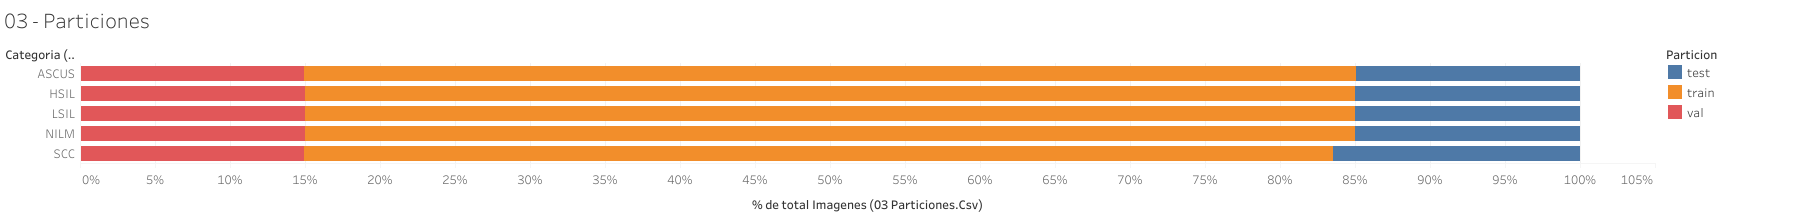

Link: https://public.tableau.com/app/profile/jorge.manuel.oyoqui.aguilera/viz/ProyectoBigData_17939473138950/03-Particiones?publish=yes

## 10. Extracción de características visuales y clasificación multiclase

### Arquitectura y justificación

Utilicé y adapté una **arquitectura híbrida** con un extractor visual preentrenado y un único clasificador entrenado para el problema. Mi arquitectura quedó de la sigueinte manera:

- **Entrada:** Imagen RGB ->
- **Ajuste a 224×224** ->
- **MobileNetV2 congelada** ->
- **vector de 1,280 características** ->
- **Regresión logística multinomial de Spark MLlib** ->
- **Output:** una de las cinco categorías.

Elegí MobileNetV2 debido a su arquitectura compacta y a la disponibilidad de pesos preentrenados que tiene en ImageNet. Utilicé la red solo y únicamente para **extraer características**, de modo que sus pesos no se actualizaron y su capa de clasificación fue reemplazada por una identidad. De esa forma pude aprovechar representaciones visuales sin entrenar una red convolucional completa con los recursos de mi proyecto.

El **modelo aprendido sobre los datos de citología** fue una regresión logística multinomial la cual implementpé con `pyspark.ml.classification.LogisticRegression`. Lo escogí gracias a su compatibilidad directa con vectores y etiquetas en DataFrames de Spark, sus métricas disponibles en MLlib y a su entrenamiento relativamente eficiente. Igualmente, utilicé regularización L2 (`regParam=0.05`), un máximo de 80 iteraciones y estandarización interna. No hice búsqueda de arquitecturas ni tampoco comparación de clasificadores, de modo que realicé un único modelo usando PySpark.

**Aclaración:** Que la red preentrenada proceda de imágenes naturales no implica que sus características vayan a ser las más óptimas para citología. Al fin y al cabo, lo que hice fue una **solución experimental**.

### 10.1. Entorno de extracción de características

Utilicé PyTorch/torchvision para la inferencia del extractor congelado.

La parte del entorno que se registró de PyTorch de **2.11.0+cpu** y de torchvision de **0.26.0+cpu** es para saber si estoy trabajando con CPU o GPU T4, y en base a eso darme una idea de qué tanto tardará mi modelo en entrenarse.

In [ ]:
import torch
import torchvision
print('PyTorch:', torch.__version__)
print('Torchvision:', torchvision.__version__)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Dispositivo seleccionado:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('Extracción ejecutada en CPU.')

PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
Dispositivo seleccionado: cpu
Extracción ejecutada en CPU.


### 10.2. Recuperación de los conjuntos preparados

A continuación, se leyeron los inventarios persistidos, verificando la disponibilidad de las **4,620 imágenes de entrenamiento**, **991 de validación** y **1,009 de prueba**. Utilicé inventarios para así evitar reconstruir la selección de archivos durante la etapa de modelado.

In [ ]:
from pathlib import Path
import pandas as pd
import kagglehub

TRAIN_FILE = PROJECT_DIR / 'inventario_train.csv'
VAL_FILE = PROJECT_DIR / 'inventario_val.csv'
TEST_FILE = PROJECT_DIR / 'inventario_test.csv'
split_data = {}
for name,path_csv in [('train',TRAIN_FILE),('val',VAL_FILE),('test',TEST_FILE)]:
    if not path_csv.exists(): raise FileNotFoundError(f'Falta {path_csv}')
    split_data[name] = pd.read_csv(path_csv)
assert sum(len(x) for x in split_data.values()) == 6620

all_paths = [Path(v) for df in split_data.values() for v in df['ruta']]
if not all(p.exists() for p in all_paths):
    print('Recuperando imágenes mediante KaggleHub...')
    source_root = Path(kagglehub.dataset_download('robiulhasan21/cervical-cancer-image-largest-dataset'))
    for name,df in split_data.items():
        df['ruta'] = [str(source_root / 'Image' / row.carpeta_padre / row.archivo) for row in df.itertuples()]
missing = [(name,row.ruta) for name,df in split_data.items() for row in df.itertuples() if not Path(row.ruta).is_file()]
if missing: raise FileNotFoundError(f'Rutas no encontradas: {missing[:5]} (total={len(missing)})')
print({k:len(v) for k,v in split_data.items()})
print('Todas las rutas están accesibles.')

{'train': 4620, 'val': 991, 'test': 1009}
Todas las rutas están accesibles.


### 10.3. Preprocesamiento y extracción

Las imágenes se convirtieron a RGB, se ajustaron a **224×224 píxeles** conservando la proporción mediante relleno blanco y se normalizaron con las medias y desviaciones utilizadas para ImageNet.

Con respecto a MobileNetV2 con pesos `IMAGENET1K_V2`, este se mantuvo en modo evaluación, sin cálculo de gradientes ni actualización de parámetros. Mientras tanto, la sustitución de la capa clasificadora por una identidad generó un vector de **1,280 características** por imagen`.

In [ ]:
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights
from torchvision import transforms
from PIL import Image, ImageOps
from torch import nn

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
WEIGHTS = MobileNet_V2_Weights.IMAGENET1K_V2
extractor = mobilenet_v2(weights=WEIGHTS)
extractor.classifier = nn.Identity()
extractor = extractor.to(DEVICE).eval()
for parameter in extractor.parameters(): parameter.requires_grad_(False)

normalizer = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
])
def prepare_image(path):
    with Image.open(path) as im:
        rgb = im.convert('RGB')
        fitted = ImageOps.contain(rgb, (224,224), method=Image.Resampling.BILINEAR)
        padded = ImageOps.pad(fitted, (224,224), method=Image.Resampling.BILINEAR, color=(255,255,255))
        return normalizer(padded)

with torch.inference_mode():
    probe = extractor(torch.zeros(1,3,224,224,device=DEVICE))
print('Dimensión del vector:',tuple(probe.shape))
assert tuple(probe.shape)==(1,1280)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 88.3MB/s]


Dimensión del vector: (1, 1280)


### 10.4. Obtención y almacenamiento de vectores

A continuación, se procesaron las imágenes en bloques de 200 y minilotes de 16. Guardé la características en archivos `.npz` con su ruta y etiqueta correspondiente. Se generaron vectores para las **6,620 imágenes** de las tres particiones, manteniendo el orden de los inventarios. Lo que hago en este paso es transformar el material visual original en datos numéricos más pequeños que sean adecuados como entrada para los algoritmos de MLlib.

In [ ]:
import numpy as np
from torch.utils.data import Dataset, DataLoader

FEATURE_DIR = PROJECT_DIR / 'caracteristicas_mobilenetv2_imagenet_v2_224_padwhite_v1'
FEATURE_DIR.mkdir(parents=True,exist_ok=True)
CHUNK_SIZE = 200
BATCH_SIZE = 16

class CytologyDataset(Dataset):
    def __init__(self, frame): self.frame=frame.reset_index(drop=True)
    def __len__(self): return len(self.frame)
    def __getitem__(self,index):
        row=self.frame.iloc[index]
        return prepare_image(row['ruta']), str(row['ruta']), str(row['carpeta_padre'])

def valid_chunk(checkpoint, expected_frame):
    if not checkpoint.exists(): return False
    try:
        with np.load(checkpoint,allow_pickle=False) as z:
            return (z['features'].shape==(len(expected_frame),1280) and
                    np.array_equal(z['paths'].astype(str),expected_frame['ruta'].astype(str).to_numpy()) and
                    np.array_equal(z['labels'].astype(str),expected_frame['carpeta_padre'].astype(str).to_numpy()))
    except Exception: return False

for split_name in ['train','val','test']:
    frame=split_data[split_name].reset_index(drop=True)
    for start in range(0,len(frame),CHUNK_SIZE):
        part=frame.iloc[start:start+CHUNK_SIZE].reset_index(drop=True)
        checkpoint=FEATURE_DIR / f'{split_name}_{start:05d}.npz'
        if valid_chunk(checkpoint,part):
            print('Recuperado:',checkpoint.name)
            continue
        loader=DataLoader(CytologyDataset(part),batch_size=BATCH_SIZE,shuffle=False,num_workers=2,pin_memory=(DEVICE.type=='cuda'))
        features,paths,labels=[],[],[]
        with torch.inference_mode():
            for xb,batch_paths,batch_labels in loader:
                fb=extractor(xb.to(DEVICE,non_blocking=True)).float().cpu().numpy()
                features.append(fb)
                paths.extend(batch_paths)
                labels.extend(batch_labels)
        array=np.concatenate(features).astype(np.float32)
        assert array.shape==(len(part),1280)
        np.savez_compressed(checkpoint,features=array,paths=np.asarray(paths),labels=np.asarray(labels))
        assert valid_chunk(checkpoint,part)
        print('Guardado:',checkpoint.name, array.shape)
print('Extracción de características finalizada.')

Guardado: train_00000.npz (200, 1280)
Guardado: train_00200.npz (200, 1280)
Guardado: train_00400.npz (200, 1280)
Guardado: train_00600.npz (200, 1280)
Guardado: train_00800.npz (200, 1280)
Guardado: train_01000.npz (200, 1280)
Guardado: train_01200.npz (200, 1280)
Guardado: train_01400.npz (200, 1280)
Guardado: train_01600.npz (200, 1280)
Guardado: train_01800.npz (200, 1280)
Guardado: train_02000.npz (200, 1280)
Guardado: train_02200.npz (200, 1280)
Guardado: train_02400.npz (200, 1280)
Guardado: train_02600.npz (200, 1280)
Guardado: train_02800.npz (200, 1280)
Guardado: train_03000.npz (200, 1280)
Guardado: train_03200.npz (200, 1280)
Guardado: train_03400.npz (200, 1280)
Guardado: train_03600.npz (200, 1280)
Guardado: train_03800.npz (200, 1280)
Guardado: train_04000.npz (200, 1280)
Guardado: train_04200.npz (200, 1280)
Guardado: train_04400.npz (200, 1280)
Guardado: train_04600.npz (20, 1280)
Guardado: val_00000.npz (200, 1280)
Guardado: val_00200.npz (200, 1280)
Guardado: val_004

En el siguiente dashboard presento la reducción del volumen mediante la extracción visual.

Link: https://public.tableau.com/app/profile/jorge.manuel.oyoqui.aguilera/viz/ProyectoBigData_17939473138950/16_Reduccindelvolumenmediantelaextraccinvisual?publish=yes

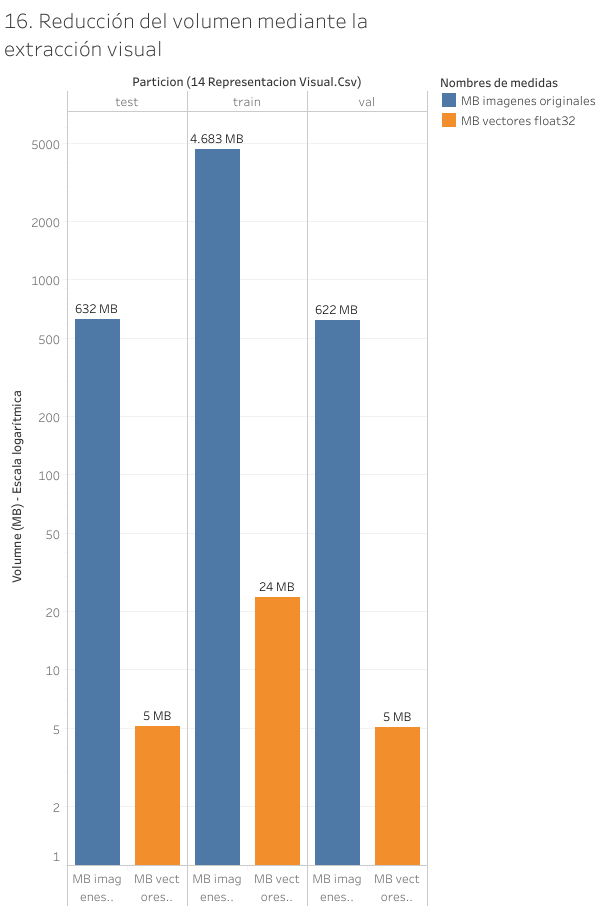

La extracción a través de MobileNetV2 me permitió representar las 6,620 imágenes con vectores de 1,280 características. Los valores numéricos de dichos vectores ocuparon aproximadamente 33.89 MB en formato float32, lo cual me permitió poder trabajar con una representación considerablemente más comparta que las imágenes originales. Luego de eso, integré sichos vectories en DataFrames de PySpark para entrenar el clasificador multinomial.  Con esta transformación pude reducir el volumen de información visual utilizado directamente por el algoritmo de clasificación.

Me gustaría aclarar que el volumen de 33.89 MB corresponder al tamño teórico de los valores numéricos de los vectores en formato float32, eso sin considerar los metadatos, compresión ni estructuras adicionales utilizadas por Spark. Así que representa una comparación de la cantidad de información almacenada en las características extraídas, no una medición del consumo total de la memoria durante el entrenamiento.

### 10.5. Entrenamiento de regresión logística multinomial con MLlib

Construí DataFrames de Spark con las columnas `ruta`, `label` y `features`, de modo que `features` contuvo un vector denso de 1,280 valores. Entrené el clasificador utilizando **solo 4,620 observaciones**, usando `family='multinomial'`, `maxIter=80`, `regParam=0.05`, `elasticNetParam=0.0` y `standardization=True`. Igualment, almacené el modelo a través de los mecanismos de persistencia de Spark.

Sobre el conjunto de validación, este se utilizó para inspeccionar el desempeño; y al conjunto de prueba lo reservé para la evaluación final.

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from pyspark.sql import SparkSession
from pyspark.ml.linalg import Vectors

spark=SparkSession.builder.appName('BigData_Citologia_MLlib').master('local[2]').config('spark.sql.shuffle.partitions','4').getOrCreate()
spark.sparkContext.setLogLevel('WARN')
FEATURE_DIR = PROJECT_DIR / 'caracteristicas_mobilenetv2_imagenet_v2_224_padwhite_v1'
CLASS_NAMES=['ASCUS','HSIL','LSIL','NILM','SCC']
CLASS_TO_ID={name:i for i,name in enumerate(CLASS_NAMES)}

def load_feature_split(name):
    csv=PROJECT_DIR / f'inventario_{name}.csv'
    df=pd.read_csv(csv).reset_index(drop=True)
    chunks=[]
    for start in range(0,len(df),200):
        file=FEATURE_DIR / f'{name}_{start:05d}.npz'
        if not file.exists(): raise FileNotFoundError(f'Falta {file}; extrae todos los bloques antes de entrenar.')
        with np.load(file,allow_pickle=False) as z:
            assert z['features'].shape==(len(df.iloc[start:start+200]),1280)
            assert np.array_equal(z['paths'].astype(str),df['ruta'].iloc[start:start+200].astype(str).to_numpy())
            assert np.array_equal(z['labels'].astype(str),df['carpeta_padre'].iloc[start:start+200].astype(str).to_numpy())
            chunks.append(z['features'].astype(np.float32))
    X=np.concatenate(chunks)
    y=df['carpeta_padre'].map(CLASS_TO_ID).to_numpy(dtype=np.int32)
    assert len(X)==len(y) and np.isfinite(X).all()
    rows=[(str(p),float(label),Vectors.dense(x.astype(float))) for p,label,x in zip(df['ruta'],y,X)]
    return spark.createDataFrame(rows,['ruta','label','features'])

train_spark=load_feature_split('train').cache()
val_spark=load_feature_split('val').cache()
test_spark=load_feature_split('test').cache()
print('Filas:',train_spark.count(),val_spark.count(),test_spark.count())

Filas: 4620 991 1009


In [ ]:
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

classifier=LogisticRegression(featuresCol='features',labelCol='label',family='multinomial',maxIter=80,regParam=0.05,elasticNetParam=0.0,standardization=True)
model=classifier.fit(train_spark)
print('Modelo entrenado. Iteraciones:',model.summary.totalIterations)
val_predictions=model.transform(val_spark).cache()
for metric in ['accuracy','f1','weightedPrecision','weightedRecall']:
    score=MulticlassClassificationEvaluator(labelCol='label',predictionCol='prediction',metricName=metric).evaluate(val_predictions)
    print(f'Validación {metric}: {score:.4f}')
MODEL_DIR=str(PROJECT_DIR / 'modelo_mllib_logistica_multinomial_v1')
model.write().overwrite().save(MODEL_DIR)
print('Modelo guardado:',MODEL_DIR)

Modelo entrenado. Iteraciones: 80
Validación accuracy: 0.5035
Validación f1: 0.4776
Validación weightedPrecision: 0.5682
Validación weightedRecall: 0.5035
Modelo guardado: /content/drive/MyDrive/BigData_Cervical_MLlib/modelo_mllib_logistica_multinomial_v1


El entrenamiento alcanzó el límite de las **80 iteraciones**. Al final, el modelo obtuvo los siguientes resultados:
- **Accuracy: 0.5035**
- **F1 ponderado: 0.4776**
- **Precision ponderada: 0.5682**
- **Recall ponderado: 0.5035**.

El F1 resume el equilibrio entre precisión y cobertura de las categorías con respecto a sus frecuencias. Justamente por ello revisé y analicé también la matriz de confusión.

**Aclaración:** Que el modelo haya alcanzado el límite de las 80 iteraciones no prueba por sí solo que haya convergido. Para firmar eso requeriría analizar el historial de la función objetivo.

Me gustaría aclarar que realicé el procesamiento del conjunto a través de una arquitectura híbrida, de modo que utilicé PySpark para estructurar los metadatos, para realizar agrupacmientos, agregaciones y cruces de información, así como apra organizar los vectores de estadísticas y entrenar el clasificador a través de Spark MLlib. Por otro lado, utilicé PyTorch para la extracción visual con MobileNetV2, debido a su compatibilidad con redes neuronales convoluciones preentrenadas.

Hice la extracción de características por lotes y almacené sus resultados de forma persistente para así evitar tener que repetir el procesamiento de las imágenes en las etapas posteriores.Igualmente, generé tablas analíticas intermediarias mediante PySpark para así poder visualizar en Tableau las características de los datos y los resultados del modelo.

A pesar de que ejecuté este proyecto en modo local y no distribuí la extracción visual mediante Spark, el integrar estas herramientas me permirió poder implementar un flujo reproducible de procesamiento, clasificación, evaluación y visualización de información.

A continuación, presento gráficamente como quedaron los resultados de validación.

Link: https://public.tableau.com/app/profile/jorge.manuel.oyoqui.aguilera/viz/ProyectoBigData_17939473138950/17_Comapracindemtricasdevalidacinyprueba2?publish=yes

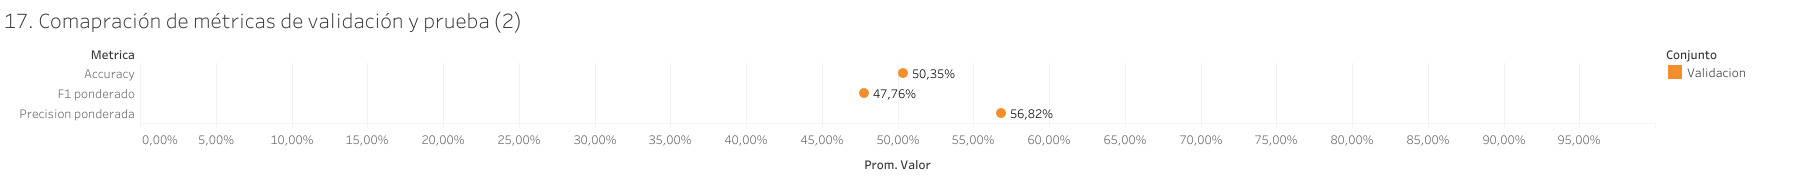

Durante la etapa de validación, el clasificador obtuvo una exactitud del 50.35%, un F1-score ponderado del 47-76% y una precisión ponderada del 56.82%. Dichas métricas me permitieron realizar una primera evaluación del desempeño del modelo antes de utilizar el conjunto de prueba. Los resultados me muestran que hubo dificultades para distinguir las categorías citológicas.

### 10.6. Evaluación del modelo y generación de predicciones

Realizó la evaluación mediante `MulticlassClassificationEvaluator` de PySpark y las predicciones generadas por `model.transform()`. Se analizaron **accuracy**, **precision ponderada**, **recall ponderado** y **F1 ponderado**. Dichas métricas describen el rendimiento general, pero no sustituyen como tal la revisión por clase mediante la matriz de confusión.

Sobre el conjunto de prueba, se utilizó para estimar el comportamiento del modelo sobre observaciones reservadas. Cabe aclarar que no utilicé los resultados de validación y prueba para entrenar MobileNetV2 ni para una nueva búsqueda de hiperparámetros.

In [ ]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.sql import functions as F
test_predictions=model.transform(test_spark).cache()
for metric in ['accuracy','f1','weightedPrecision','weightedRecall']:
    score=MulticlassClassificationEvaluator(labelCol='label',predictionCol='prediction',metricName=metric).evaluate(test_predictions)
    print(f'Prueba {metric}: {score:.4f}')

def export_predictions(pred_df, split_name):
    selected=pred_df.select('ruta','label','prediction','probability').collect()
    records=[]
    for row in selected:
        item={'ruta':row['ruta'],'real':CLASS_NAMES[int(row['label'])],
              'predicha':CLASS_NAMES[int(row['prediction'])],
              'correcta':int(row['label']==row['prediction'])}
        item.update({f'prob_{cls}':float(row['probability'][i]) for i,cls in enumerate(CLASS_NAMES)})
        records.append(item)
    table=pd.DataFrame(records)
    table.to_csv(PROJECT_DIR / f'tableau_predicciones_{split_name}.csv',index=False)
    print(split_name, 'predicciones exportadas:',len(table))
    return table

val_results=export_predictions(val_predictions,'val')
test_results=export_predictions(test_predictions,'test')
display(pd.crosstab(test_results['real'],test_results['predicha']))

Prueba accuracy: 0.5183
Prueba f1: 0.5005
Prueba weightedPrecision: 0.5892
Prueba weightedRecall: 0.5183
val predicciones exportadas: 991
test predicciones exportadas: 1009


predicha,ASCUS,HSIL,LSIL,NILM,SCC
real,,,,,
ASCUS,14,99,9,16,6
HSIL,2,160,42,5,2
LSIL,5,136,50,9,2
NILM,10,12,9,238,0
SCC,16,103,2,1,61


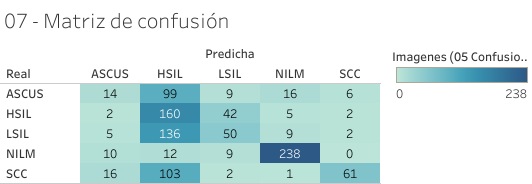

Link: https://public.tableau.com/app/profile/jorge.manuel.oyoqui.aguilera/viz/ProyectoBigData_17939473138950/07-Matrizdeconfusin?publish=yes

### 10.7. Interpretación de los resultados finales

El conjunto de prueba obtuvo los siguientes resultados:
- **Accuracy: 0.5183**
- **F1 ponderado: 0.5005**
- **Precision ponderada: 0.5892**
- **Recall ponderado: 0.5183**

En términos absolutos, hubo **523 predicciones correctas de 1,009 imágenes**. La buena noticia es que las métricas de prueba quedaron próximas a las de validación, lo cual sugiere que hubo estabilidad en estas particiones, pero me temo que no demuestró poder generalizar entre instituciones o pacientes independientes.

| Clase | Precision | Recall | F1 | Soporte de prueba |
|---|---:|---:|---:|---:|
| ASCUS | 0.2979 | 0.0972 | 0.1466 | 144 |
| HSIL | 0.3137 | 0.7583 | 0.4438 | 211 |
| LSIL | 0.4464 | 0.2475 | 0.3185 | 202 |
| NILM | 0.8848 | 0.8848 | 0.8848 | 269 |
| SCC | 0.8592 | 0.3333 | 0.4803 | 183 |

La categoría **NILM** mostró el mejor equilibrio (precision y recall de 88.48%). **HSIL** alcanzó un recall elevado (del 75.83%), pero su precision fue baja (siendo de 31.37%). Eso significa que de las **510 predicciones HSIL, únicamente 160** correspondían a esa clase. Se confundieron con HSIL **99 imágenes ASCUS**, **136 LSIL** y **103 SCC**. ASCUS fue el que tuvo el menor recall (**9.72%**) y SCC solo recuperó **33.33%** de sus ejemplos reales.

Los resultados indican que el clasificador aprendió algunas señales útiles, pero sigue presentando confusiones considerables. Su accuracy supera el 26.7% aproximado que se obtendría al predecir siempre la clase mayoritaria del conjunto de prueba (NILM), aunque **51.83% sigue sin ser suficiente como para atribuirle utilidad diagnóstica**. Entre las explicaciones de porqué sucedió esto se encuentran las limitaciones de transferir características de ImageNet, las fronteras lineales del clasificador, las posibles inconsistencias residuales de etiquetas y los efectos de procedencia. Es decir, no se puede aislar causalmente una de estas explicaciones con la evidencia disponible.

Pero finalmente la implementación cumplió con el objetivo tecnológico de construir y evaluar un clasificador con Spark MLlib, aún si sus resultados no fueron de lo más favoreble.

A continuación, presentaré visualmente cómo quedó la comparación de métricas de validación y prueba.

Link: https://public.tableau.com/app/profile/jorge.manuel.oyoqui.aguilera/viz/ProyectoBigData_17939473138950/17_Comapracindemtricasdevalidacinyprueba?publish=yes

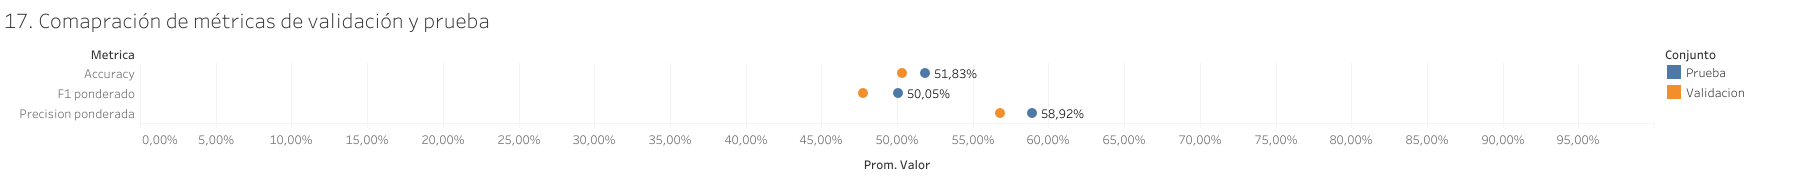

La comparación de métricas muestraque hubo un desempeño simular entre validación y prueba. La exactitud pasó de 50.35% a 51.83%, mientras que el F1 ponderado aumentó de 47.76% a 50.05%. No vi que hubiera una caída importante del rendimiento en el conjunto de prueba, aunque los resultados de los dos conjuntos muestran qye hubieron limitaciones en la capacidad predictiva. Así que cone sta comparación puedo evaluar cómo fue la estabilidad del modelo dentro de las peticiones utilizadas, sin garantizar su generalización a nuevas fuentes o pacientes.

Igualmente presento visualente cómo fue el accuracy según la resolución original.

Link: https://public.tableau.com/app/profile/jorge.manuel.oyoqui.aguilera/viz/ProyectoBigData_17939473138950/18_Accuracysegnlaresolucinoriginal?publish=yes

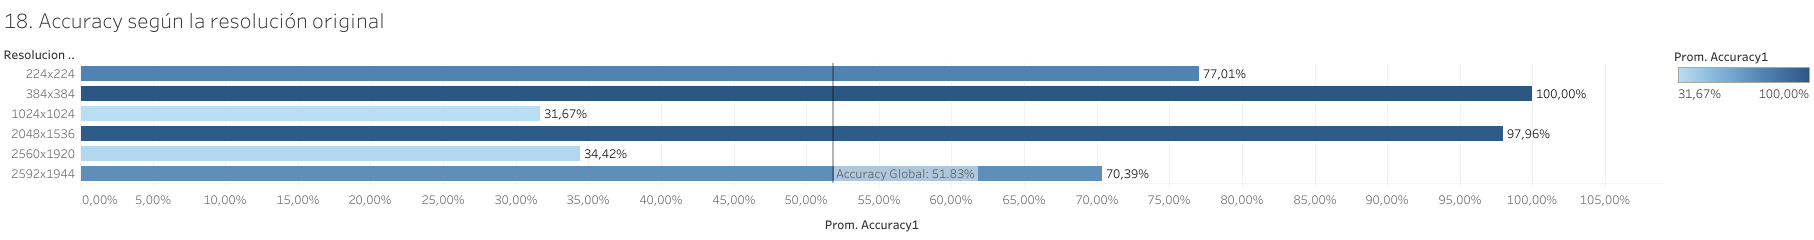

La evaluación del clasificador según la resolución originla de las imágenes me permitió poder identificar diferencias considerablemente importantes en su desempeño. Las resoluciones de 384 x 384 y 2048 x 1536 píxeles alcanzaron una exactitud del 100% y 97.96% respectivamente, mientras que als de 1024 x 1024 y 2560 x 1920 obtuvieron resultados considerablemente inferiores, siendo de 31.67% y 34.42% respectivamente.

Dicho resultados sugieren que las características de adquisición y la composición de las categorías dentro de cada resolución podrían llegar a estar asociadas con el rendimiento del modelado.

Pero me temo que las diferencias observadas no me permitieron afirmar que la resolución es la causa directa del desempeño. Otros aspectos que considero importantes tomar en cuenta son la cantidad de imágenes evaluadas, la distribución de las categorías y las posibles diferencias entre las fuentes originales. Así que este dashboard me es útil para poder identificar los segmentos del conjunto de datos que requieren más atención y comprender las limitaciones que tiene el accuracy normal.

Igualmente, agrego un dashboard con el recall por clase (sólo que no voy a indagar mucho en él ya que eso lo haré en la sección 11).

Link: https://public.tableau.com/app/profile/jorge.manuel.oyoqui.aguilera/viz/ProyectoBigData_17939473138950/06-Recallporclase?publish=yes

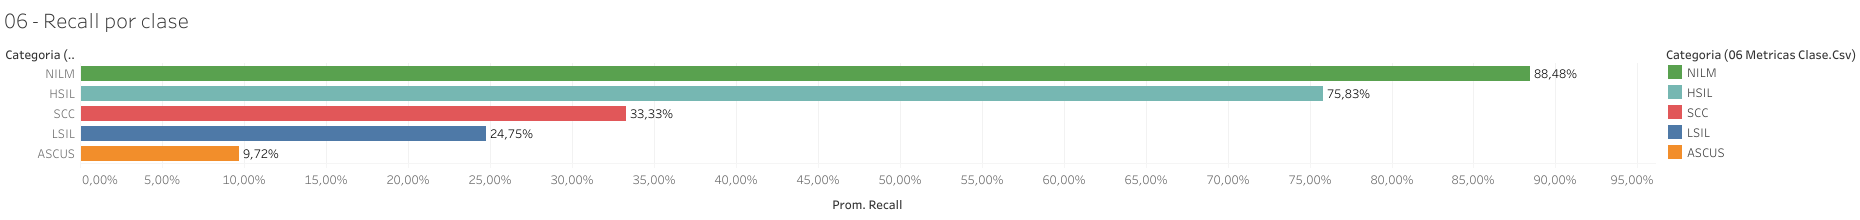

## 11. Visualización administrada: Tableau

A lo alrgo del poyecto se generaron archivos CSV con estadísticas por clase, resoluciones, particiones y predicciones del clasificador. Dichos resultados me van a permitir diseñar un tablero administrado en **Tableau**, con visualizaciones de la distribución original y depurada de categorías, relación entre resolución y clase, particiones, métricas y matriz de confusión.

Igualmente comparto la URL pública del dashboard:

Para construir el tablero, primero tuve que recuperar algunos de los CSV que generé previamente, donde los que utilicé fueron:
- `tableau_resumen_clases.csv`:	Cantidad y tamaño de imágenes por categoría original
- `inventario_particiones_completo.csv`:	Imágenes limpias y partición asignada
- `tableau_resolucion_clase.csv`:	Cantidad de imágenes por resolución y clase
- `tableau_predicciones_test.csv`:	Etiquetas reales, predicciones y probabilidades
- `inventario_imagenes.csv`:	Formatos y tamaños de los archivos originales

Algo importante que quiero recalcar es que como voy a publicar el dashboard, y algunos CSV contienen rutas completas de las imágenes, voy a estar utilizando únicamente tablas agregadas.

In [ ]:
import pandas as pd
from pathlib import Path

from google.colab import drive
drive.mount("/content/drive")

BASE = Path("/content/drive/MyDrive/BigData_Cervical_MLlib")
SALIDA = BASE / "Tablas_Tableau"
SALIDA.mkdir(exist_ok=True)

# Archivos que ya generamos
original = pd.read_csv(BASE / "tableau_resumen_clases.csv")
particiones = pd.read_csv(BASE / "inventario_particiones_completo.csv")
resoluciones = pd.read_csv(BASE / "tableau_resolucion_clase.csv")
predicciones = pd.read_csv(BASE / "tableau_predicciones_test.csv")
inventario = pd.read_csv(BASE / "inventario_imagenes.csv")


# 1. Comparación original vs limpio
conteo_original = (
    original[["carpeta_padre", "n_imagenes"]]
    .rename(columns={
        "carpeta_padre": "categoria",
        "n_imagenes": "imagenes"
    })
)
conteo_original["etapa"] = "Original"

conteo_limpio = (
    particiones.groupby("carpeta_padre")
    .size()
    .reset_index(name="imagenes")
    .rename(columns={"carpeta_padre": "categoria"})
)
conteo_limpio["etapa"] = "Limpio"

comparacion = pd.concat(
    [conteo_original, conteo_limpio],
    ignore_index=True
)
comparacion.to_csv(SALIDA / "01_comparacion_clases.csv", index=False)


# 2. Distribución de formatos
formatos = (
    inventario.groupby("extension")
    .size()
    .reset_index(name="imagenes")
)
formatos.to_csv(SALIDA / "02_formatos.csv", index=False)


# 3. Distribución de particiones
distribucion = (
    particiones.groupby(["carpeta_padre", "particion"])
    .size()
    .reset_index(name="imagenes")
    .rename(columns={"carpeta_padre": "categoria"})
)
distribucion.to_csv(SALIDA / "03_particiones.csv", index=False)


# 4. Resolución por categoría (formato largo)
res_col = resoluciones.columns[0]

resoluciones_largo = resoluciones.melt(
    id_vars=res_col,
    var_name="categoria",
    value_name="imagenes"
)
resoluciones_largo = resoluciones_largo.rename(
    columns={res_col: "resolucion"}
)
resoluciones_largo.to_csv(
    SALIDA / "04_resolucion_clase.csv",
    index=False
)


# 5. Matriz de confusión
clases = ["ASCUS", "HSIL", "LSIL", "NILM", "SCC"]

confusion = (
    predicciones.groupby(["real", "predicha"])
    .size()
    .reindex(
        pd.MultiIndex.from_product(
            [clases, clases],
            names=["real", "predicha"]
        ),
        fill_value=0
    )
    .reset_index(name="imagenes")
)
confusion.to_csv(SALIDA / "05_confusion.csv", index=False)


# 6. Métricas por clase
metricas = []

for clase in clases:
    tp = ((predicciones["real"] == clase) &
          (predicciones["predicha"] == clase)).sum()

    pred_total = (predicciones["predicha"] == clase).sum()
    real_total = (predicciones["real"] == clase).sum()

    precision = tp / pred_total if pred_total else 0
    recall = tp / real_total if real_total else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    metricas.append({
        "categoria": clase,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "soporte": real_total,
        "errores": real_total - tp
    })

pd.DataFrame(metricas).to_csv(
    SALIDA / "06_metricas_clase.csv",
    index=False
)

print("Archivos preparados:")
for archivo in sorted(SALIDA.glob("*.csv")):
    print(archivo.name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Archivos preparados:
01_comparacion_clases.csv
02_formatos.csv
03_particiones.csv
04_resolucion_clase.csv
05_confusion.csv
06_metricas_clase.csv


Ya con esos CSV, desarrollé varios gráficos en Tableau, obtiendo finalmente los dashborads finales.

Igualmente utilicé las siguientes tablas analíticas para generar los dashboards intermedios:

In [ ]:
# Tablas analíticas intermedias

from pathlib import Path
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
import pandas as pd

BASE = Path("/content/drive/MyDrive/BigData_Cervical_MLlib")
SALIDA = BASE / "Tablas_Tableau"
SALIDA.mkdir(parents=True, exist_ok=True)

spark = (
    SparkSession.builder
    .appName("BigData_Citologia_Analisis_Intermedio")
    .master("local[2]")
    .config("spark.sql.shuffle.partitions", "4")
    .getOrCreate()
)

# Leer los resultados previamente almacenados
def leer_csv(nombre):
    return (
        spark.read
        .option("header", True)
        .option("inferSchema", True)
        .csv(str(BASE / nombre))
    )

def exportar(df, nombre):
    # Solo se trasladan a Pandas las tablas analíticas finales
    df.toPandas().to_csv(SALIDA / nombre, index=False)
    print("Generado:", nombre)

inventario = leer_csv("inventario_imagenes.csv")
calidad = leer_csv("metadatos_calidad_completos.csv")
patrones = leer_csv("patrones_nombres.csv")
familias = leer_csv("familias_candidatas.csv")
particiones = leer_csv("inventario_particiones_completo.csv")
predicciones = leer_csv("tableau_predicciones_test.csv")


# 7. Contribución de los datasets originales
# Datos declarados en la descripción del dataset en Kaggle
origenes = spark.createDataFrame([
    ("CytologCervicalCancer", 2545),
    ("BiCervi", 2692),
    ("RIVA", 941),
    ("APCEM", 1163)
], ["dataset_origen", "imagenes"])

exportar(origenes, "07_datasets_origen.csv")


# 8. Volumen de almacenamiento por extensión
volumen = (
    inventario.groupBy("extension")
    .agg(
        F.count("*").alias("imagenes"),
        F.sum("bytes").alias("bytes_totales"),
        (F.avg("bytes") / 1e6).alias("MB_promedio")
    )
    .withColumn("MB_totales", F.col("bytes_totales") / 1e6)
    .withColumn("GB_totales", F.col("bytes_totales") / 1e9)
    .orderBy(F.desc("MB_totales"))
)

exportar(volumen, "08_volumen_extension.csv")


# 9. Distribución de resoluciones
resolucion_original = (
    calidad
    .filter(F.col("valida").cast("boolean") == True)
    .withColumn(
        "megapixeles",
        F.col("ancho").cast("double") *
        F.col("alto").cast("double") / 1e6
    )
    .withColumn(
        "resolucion",
        F.concat_ws("x", "ancho", "alto")
    )
)

# Intervalos de 0.5 megapíxeles para el histograma
histograma = (
    resolucion_original
    .withColumn(
        "intervalo_MP",
        F.floor(F.col("megapixeles") / 0.5) * 0.5
    )
    .groupBy("intervalo_MP")
    .agg(F.count("*").alias("imagenes"))
    .orderBy("intervalo_MP")
)

exportar(histograma, "09_histograma_megapixeles.csv")


# 10. Calidad de etiquetas y duplicados
grupos_hash = (
    calidad
    .filter(F.col("sha256").isNotNull() & (F.col("sha256") != ""))
    .groupBy("sha256")
    .agg(
        F.count("*").alias("n_archivos"),
        F.countDistinct("carpeta_padre").alias("n_clases")
    )
)

estado_hash = (
    calidad
    .join(grupos_hash, on="sha256", how="inner")
    .withColumn(
        "estado",
        F.when(
            F.col("n_clases") > 1,
            "Conflicto de etiquetas"
        ).when(
            F.col("n_archivos") > 1,
            "Duplicado consistente"
        ).otherwise("Archivo unico")
    )
    .groupBy("carpeta_padre", "estado")
    .agg(F.count("*").alias("imagenes"))
    .withColumnRenamed("carpeta_padre", "categoria")
)

exportar(estado_hash, "10_estado_duplicados.csv")


# 11. Patrones de nombres
prefijos = (
    patrones
    .groupBy("carpeta_padre", "prefijo_inicial")
    .agg(F.count("*").alias("imagenes"))
    .withColumnRenamed("carpeta_padre", "categoria")
)

exportar(prefijos, "11_prefijos_clase.csv")


# 12. Relación entre volumen y cantidad por clase
resumen_clase = (
    inventario
    .groupBy("carpeta_padre")
    .agg(
        F.count("*").alias("imagenes"),
        (F.sum("bytes") / 1e9).alias("GB_totales"),
        (F.avg("bytes") / 1e6).alias("MB_promedio")
    )
    .withColumnRenamed("carpeta_padre", "categoria")
)

exportar(resumen_clase, "12_volumen_clase.csv")


# 13. Tamaño de familias candidatas
familias_resumen = (
    familias
    .withColumn(
        "tipo_patron",
        F.split(F.col("grupo_candidato"), ":").getItem(0)
    )
    .withColumn(
        "categoria",
        F.split(F.col("grupo_candidato"), ":").getItem(1)
    )
    .withColumn(
        "rango_tamano",
        F.when(F.col("n_imagenes") <= 5, "01. 2-5")
        .when(F.col("n_imagenes") <= 10, "02. 6-10")
        .when(F.col("n_imagenes") <= 25, "03. 11-25")
        .when(F.col("n_imagenes") <= 50, "04. 26-50")
        .when(F.col("n_imagenes") <= 100, "05. 51-100")
        .otherwise("06. Mas de 100")
    )
    .groupBy("tipo_patron", "rango_tamano")
    .agg(
        F.count("*").alias("familias"),
        F.sum("n_imagenes").alias("imagenes")
    )
)

exportar(familias_resumen, "13_tamano_familias.csv")


# 14. Volumen de la representación visual
# MobileNetV2 generó 1280 valores float32 por imagen.
# Cada valor float32 ocupa 4 bytes.

representacion = (
    particiones
    .join(
        inventario.select("ruta", "bytes"),
        on="ruta",
        how="inner"
    )
    .groupBy("particion")
    .agg(
        F.count("*").alias("imagenes"),
        (F.sum("bytes") / 1e6).alias("MB_imagenes_originales")
    )
    .withColumn(
        "MB_vectores_float32",
        F.col("imagenes") * 1280 * 4 / 1e6
    )
)

exportar(representacion, "14_representacion_visual.csv")


# 15. Métricas de validación y prueba
# Resultados registrados en las secciones 10.5 y 10.7
metricas_globales = spark.createDataFrame([
    ("Validacion", "Accuracy", 0.5035),
    ("Validacion", "F1 ponderado", 0.4776),
    ("Validacion", "Precision ponderada", 0.5682),
    ("Prueba", "Accuracy", 0.5183),
    ("Prueba", "F1 ponderado", 0.5005),
    ("Prueba", "Precision ponderada", 0.5892)
], ["conjunto", "metrica", "valor"])

exportar(metricas_globales, "15_metricas_globales.csv")


# 16. Rendimiento según la resolución original
pred_resolucion = (
    predicciones
    .join(
        calidad.select("ruta", "ancho", "alto"),
        on="ruta",
        how="inner"
    )
    .withColumn(
        "resolucion",
        F.concat_ws("x", "ancho", "alto")
    )
    .withColumn(
        "acierto",
        F.when(F.col("real") == F.col("predicha"), 1)
         .otherwise(0)
    )
)

# Comprobar que se conservaron todas las predicciones
assert pred_resolucion.count() == 1009

rendimiento_resolucion = (
    pred_resolucion
    .groupBy("resolucion")
    .agg(
        F.count("*").alias("imagenes"),
        F.sum("acierto").alias("aciertos"),
        F.avg("acierto").alias("accuracy")
    )
    .withColumn(
        "errores",
        F.col("imagenes") - F.col("aciertos")
    )
)

exportar(rendimiento_resolucion, "16_accuracy_resolucion.csv")

print("\nArchivos disponibles en:")
print(SALIDA)

for archivo in sorted(SALIDA.glob("*.csv")):
    print(archivo.name)

Generado: 07_datasets_origen.csv
Generado: 08_volumen_extension.csv
Generado: 09_histograma_megapixeles.csv
Generado: 10_estado_duplicados.csv
Generado: 11_prefijos_clase.csv
Generado: 12_volumen_clase.csv
Generado: 13_tamano_familias.csv
Generado: 14_representacion_visual.csv
Generado: 15_metricas_globales.csv
Generado: 16_accuracy_resolucion.csv

Archivos disponibles en:
/content/drive/MyDrive/BigData_Cervical_MLlib/Tablas_Tableau
01_comparacion_clases.csv
02_formatos.csv
03_particiones.csv
04_resolucion_clase.csv
05_confusion.csv
06_metricas_clase.csv
07_datasets_origen.csv
08_volumen_extension.csv
09_histograma_megapixeles.csv
10_estado_duplicados.csv
11_prefijos_clase.csv
12_volumen_clase.csv
13_tamano_familias.csv
14_representacion_visual.csv
15_metricas_globales.csv
16_accuracy_resolucion.csv


### 11.1. Dashboard 1: Exploración y procesamiento de datos

El primer dashboard fue para visualizar las principales características del conjunto de datos y los resultados de su preparación. Recordemos que inicialmente trabajé con 7,341 imágenes, de las cuales se conservaron 6,620 después de que eliminara los duplicados exactos y archivos con etiquetas contradictorias, lo que representó una reducción del 9.82% de mis datos totales.

A su vez, noté un predominio de archivos con extensión JPG (81.95%) y una distribución de clases moderadamente desbalanceada, donde NILM presentó la mayor cantidad de imágenes. Las particiones de entrenamiento, validación y prueba conservaron proporciones cercanas al 70%, 15% y 15% respectivamente.

Por último, el mapa de calor de resolución y categiría mostró una asociación importante entre la resolución y la categoría citológica. Dicho hallazgo sugiere que podrían existir diferencias relacionadas con las fuentes originales de adquisición, lo que igualmente termina siendo una posible limitación para la generalización de mi modelo.

En conjunto, estas visualizaciones demostraron la importancia de explorar, depurar y comprender los datos antes de utilizarlos en un proceso de aprendizaje automático.

A continuación, comparto la liga a dicho dashboard: https://public.tableau.com/views/ProyectoBigData_17939473138950/Dashboard1_Exploracinyprocesamientodeldataset?:language=es-ES&publish=yes&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link


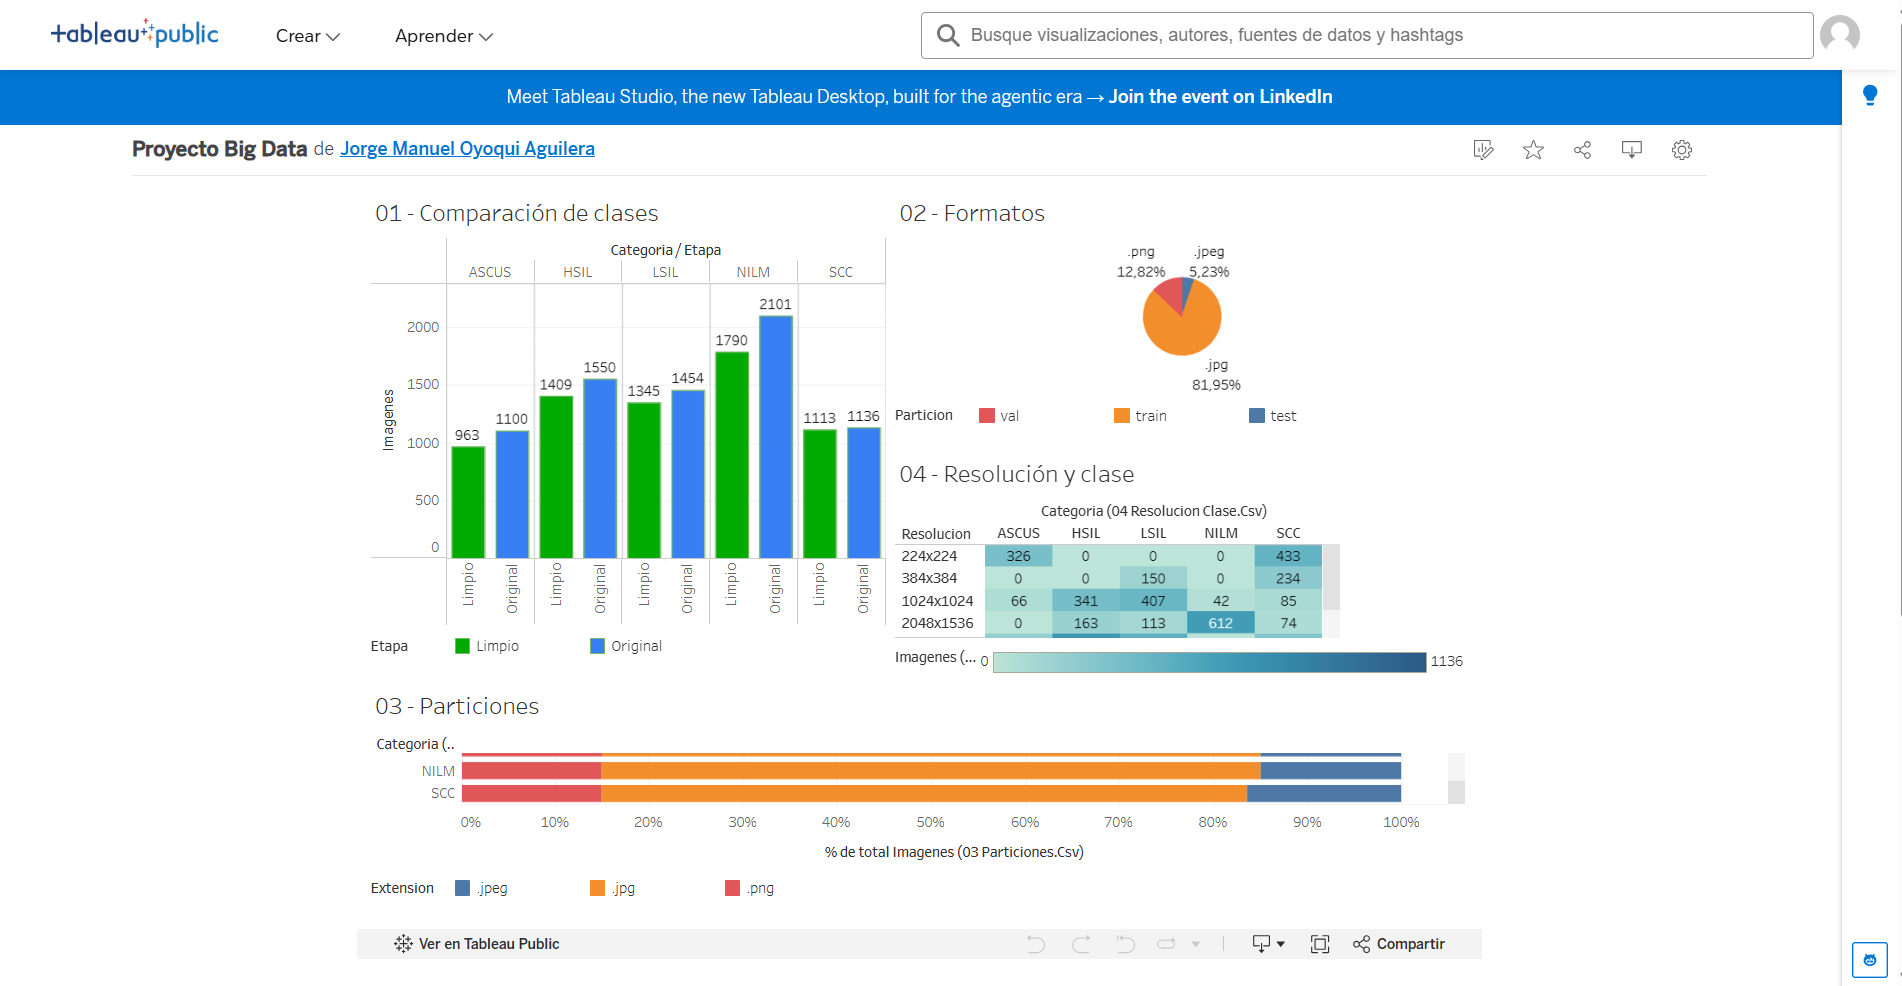



### 11.2. Dashboard 2: Evaluación del modelo

En el segundo dashboard me enfoqué más en la evaluación del desempeño del clasificador multinomial entrenado mediante PySpark MLlib. En el conjunto de prueba, el modelo obtuvo una exactitud del 51.83% y un F1-score ponderado del 50.05%, evidenciando una capacidad de clasificación limitada.

El análisis por categoría noté que NILM presentó el mejor desempeño, teniendo un recall del 88.48%, mientras que ASCUS y LSIL obtuvieron valores de 9.72% y 24.75%, respectivamente. Con respecto a la matriz de confusión, esta me permitió identificar una tendencia a clasificar incorrectamente imágenes de distintas categorías como HSIL, sobre todo en los casos de ASCUS, LSIL y SCC.

Dichos resultados sugieren que las características que extrajo MobileNetV2, combinadas con un clasificador lineal, no fueron suficientes como para distinguir adecuadamente todas las categorías citológicas. Pero a pesar de eso, el modelo logró identificar ciertos patrones y permitió evaluar sus fortalezas y debilidades a través de las herramientas de Spark MLlib.

Por ende, aún cuando su desempeño no resultó ser el adecuado para aplicaciones clínicas, el modelo cumplió su propósito experimental dentro del proyecto.

A continuación, comparto la liga a dicho dashboard: https://public.tableau.com/views/ProyectoBigData_17939473138950/Dashboard2_EvaluacindelclasificadorMLlib?:language=es-ES&publish=yes&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link

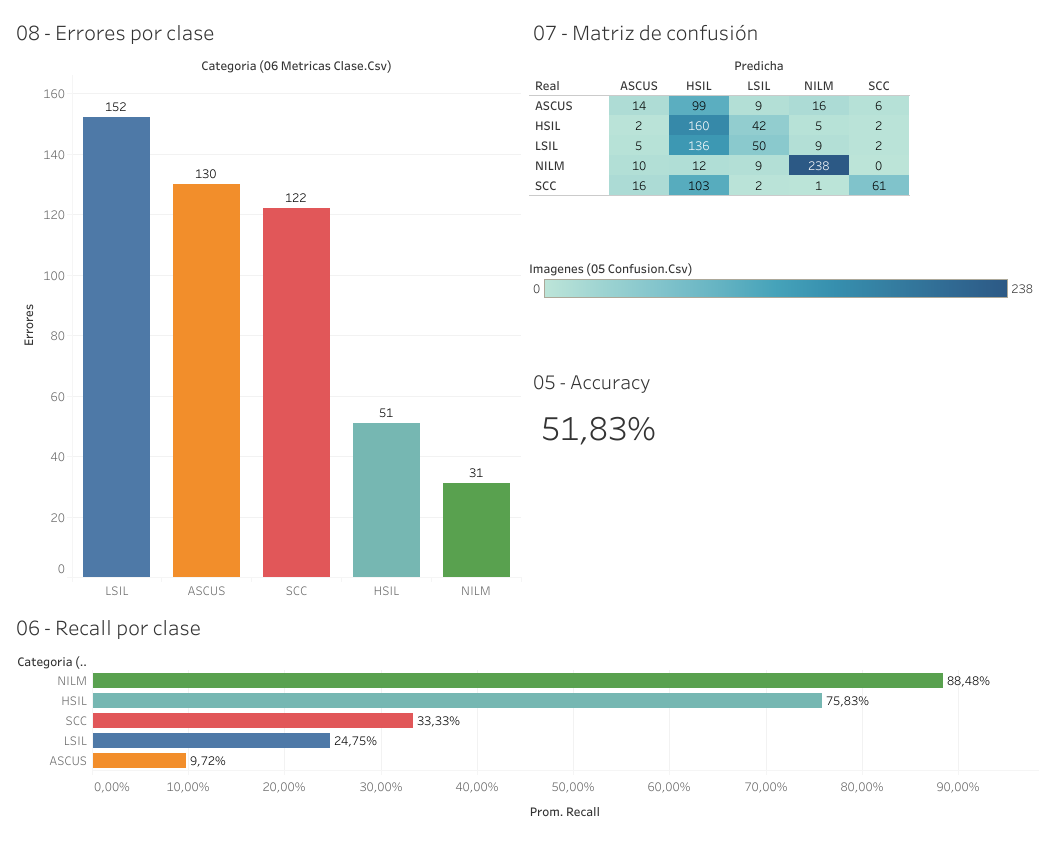

## 12. Conclusiones Finales

El desarrollo de este proyecto me permitió aplicar herramientas de Big Data y aprendizaje automático para procesar, analizar y clasificar un conjunto de imágenes de citología cervical con un volumen aproximado de 6.812 GB.

A través de PySpark, pude realizar la organización y agregación de información utilizando DataFrames, mientras que con Spark MLlib pude entrenar y evaluar un modelo de regresión logística multinomial. Para representar las características visuales de las imágenes utilicé MobileNetV2 preentrenada, evitando así la necesidad de tener que entrenar una red neuronal convolucional desde cero. Por su parte, Tableau me facilitó el desarrollar recursos de visualización de las características del conjunto y la interpretación del desempeño obtenido.

Yo diría que uno de mis principales aprendizajes fue reconocer que un mayor volumen de información no necesariamente garantiza que se van a obtener mejores resultados predictivos. Durante el procesamiento identifiqué varios duplicados, etiquetas contradictorias y posibles diferencias entre las fuentes originales, lo que me mostró la importancia de la calidad de los datos. Aunque el modelo obtuvo una exactitud del 51.83%, sus resultados mostraron dificultades para distinguir algunas categorías, particularmente ASCUS, LSIL y SCC.

Como oportunidades de mejora siento que, si continuara con este poryecto en el guturo, debería mejorar la validación de las etiquetas, la disponibilidad de identificadores clínicos para realizar particiones independientes y también el uso de representaciones que sean visuales más especializadas. Pero me temo que dichas mejoras requerirían de estudios adicionales y se encuentran fuera del alcance que definí para mi proyecto.

En conclusión, logré implementar un proceso completo de procesamiento, clasificación, evaluación y visualización mediante tecnologías de Big Data. Y dejando de lado el desempeño predictivo que tuvo mi modelo, esta experiencia me permitió comprender mejor la importancia de la preparación de datos, la selección justificada de herramientas y la interpretación crítica de los resultados, aprendiendo a reconocer tanto las capacidades como las limitaciones que tienen los modelos de aprendizaje automático.

## 13. Link de este archivo en el reporsitorio

Este archivo se puede encontrar en la siguiente dirección: https://github.com/AIPorDefinir/ai-model-tutsipink/blob/main/src/bigdata/visualizacion/a01711783_jorge_oyoqui.ipynb

Viene bajo el nombre de: Jorge Oyoqui_Proyecto Módulo 6 Big Data.ipynb


